In [11]:
from dotenv import load_dotenv

# Load connection variables into environment
load_dotenv()

True

In [12]:
# JupySQL / SQLAlchemy connection
%reload_ext sql
%reload_ext mermaid_magic

# Read connection strings from environment variables
%sql $PG_CONN --alias pg
%sql $MSSQL_CONN --alias mssql
%sql $ORACLE_CONN --alias oracle


Connecting and switching to connection 'pg'

Connecting and switching to connection 'mssql'

Connecting and switching to connection 'oracle'

# Programowanie baz danych — Wykład 2
## SELECT — od pierwszego zapytania do złączeń, podzapytań i hierarchii

**Tryb pracy:** Jupyter Notebook + JupySQL + SQL wykonywany na żywo

**DBMS używane w kursie:**
- PostgreSQL
- Microsoft SQL Server
- Oracle

**Baza demonstracyjna:** Chinook

---

### Główna idea wykładu

Wykład poświęcony jest **pobieraniu danych** — poleceniu `SELECT` i jego klauzulom. Budujemy kolejne warstwy jednego polecenia:

**proste `SELECT` → `SELECT` z wyrażeniami → `DISTINCT` i aliasy → `WHERE` → funkcje wbudowane (znakowe, matematyczne, daty) → `ORDER BY` → `GROUP BY` + agregaty → `HAVING` → podzapytania → **złączenia poziome (`JOIN`)** → operatory zbiorowe → hierarchie**

W każdej warstwie obserwujemy trzy DBMS naraz: co jest standardem ANSI SQL, a co jest rozszerzeniem lub różnicą dialektu (Oracle SQL, T-SQL, PostgreSQL).

Pytanie przewodnie: **jak z jednego polecenia `SELECT` zbudować precyzyjne pytanie o dane, zrozumiałe — i wykonywalne — w każdym z trzech systemów?**

## Cele wykładu

Po zakończeniu wykładu student powinien potrafić:

1. opisać miejsce `SELECT` (DQL) wśród grup poleceń SQL (DDL, DML, DCL, TCL),
2. odczytać strukturę istniejących tabel z metadanych (information_schema / widoki słownikowe Oracle),
3. napisać zapytanie `SELECT` z klauzulami `FROM`, `WHERE`, `GROUP BY`, `HAVING`, `ORDER BY`,
4. wyjaśnić różnicę między kolejnością *zapisu* a kolejnością *wykonania* klauzul,
5. stosować `DISTINCT`, literały, aliasy i operatory arytmetyczne,
6. wyjaśnić semantykę `NULL` i trójwartościową logikę wartości logicznych (3VL),
7. dobierać operatory selekcji: porównania, `BETWEEN`, `IN`, `LIKE`, `IS NULL` oraz priorytety `NOT`/`AND`/`OR`,
8. porządkować wyniki wg kolumny, wyrażenia, aliasu i pozycji (`ORDER BY 2 DESC`),
9. grupować wiersze i obliczać agregaty: `COUNT`, `SUM`, `AVG`, `MIN`, `MAX` — także z `DISTINCT`,
10. wyjaśnić wpływ `NULL` na wyniki funkcji agregujących,
11. stosować funkcje warunkowe `NVL`/`NVL2`/`ISNULL`/`COALESCE` oraz `DECODE`/`CASE`,
12. używać podstawowych funkcji wbudowanych: znakowych (`LENGTH`/`LEN`, `SUBSTR`, `CONCAT`, `TRIM`, `INITCAP`), matematycznych (`ROUND`, `TRUNC`, `MOD`, `CEIL`, `FLOOR`) oraz daty i czasu (`SYSDATE`/`GETDATE()`/`CURRENT_DATE`, `TO_CHAR`, `EXTRACT`, `DATEDIFF`, różnice dat między dialektami),
13. filtrować grupy klauzulą `HAVING`, także z podzapytaniem,
14. konstruować podzapytania w `WHERE`, `FROM`, `SELECT` i `HAVING` — skorelowane i nieskorelowane,
15. stosować operatory `IN`, `ANY`, `ALL`, `EXISTS`/`NOT EXISTS` wobec podzapytań,
16. łączyć wyniki operatorami zbiorowymi `UNION`, `UNION ALL`, `INTERSECT`, `MINUS`/`EXCEPT`,
17. łączyć tabele złąceniami poziomymi: `JOIN ... ON`, `USING`, `NATURAL JOIN`, złączenia zewnętrzne `LEFT/RIGHT/FULL`, self-join, semi-join (przez `EXISTS`), anti-join (`LEFT JOIN ... IS NULL`) oraz starą składnię Oracle z `(+)`,
18. rozpoznawać różnice dialektowe złączeń (`USING`/`NATURAL` bez SQL Servera, `MINUS` vs `EXCEPT`) i starać się o składnię przenośną,
19. przetwarzać hierarchie: `CONNECT BY` w Oracle oraz rekurencyjne CTE w PostgreSQL i SQL Serverze.

## 1. SQL — standard i dialekty

SQL (ang. *Structured Query Language*) jest międzynarodowym standardem utrzymywanym przez:

- **ANSI** (American National Standards Institute),
- **ISO/IEC** (International Organization for Standardization / International Electrotechnical Commission).

Obie organizacje publikują technicznie identyczne wersje standardu w formacie **ISO/IEC 9075-N:YYYY**: SQL1 (ISO 1987), SQL2 (1992), SQL3 (1999), SQL:2003, SQL:2006, SQL:2008, SQL:2011, SQL:2016, SQL:2019, **SQL:2023**.

> **Ciekawostka.** SQL powstał w IBM — opracowali go Donald D. Chamberlin i Raymond F. Boyce na podstawie relacyjnego modelu Edgara F. Codda (początek lat 70.). Pierwotna nazwa **SEQUEL** (*Structured English Query Language*) nawiązywała do wcześniejszego języka QUEL; wcześniejszą próbą był SQUARE. SEQUEL służył do manipulowania i pobierania danych z systemu IBM **System R**.

Standard to jednak nie wszystko — każdy DBMS implementuje go po swojemu:

| Cecha | Standard (ANSI/ISO) | Oracle | PostgreSQL | SQL Server |
|---|---|---|---|---|
| Schematy | katalog → schemat (SQL:1992) | osobne przestrzenie nazw w ramach jednej bazy | schemy w ramach każdej bazy (domyślna `public`) | każda baza ma własne schematy; użytkownicy zwykle działają w kontekście `dbo` |
| Identyfikatory bez cudzysłowów | składane do wielkich liter (SQL:1992) | `Employee` → `EMPLOYEE` — zgodnie ze standardem | `Employee` → `employee` — odchylenie od standardu | zapis zachowywany, porównywanie wg collation (zwykle bez rozróżniania liter) |
| Identyfikatory w cudzysłowie | rozróżniają wielkość liter (SQL:1992) | rozróżniają wielkość liter | rozróżniają wielkość liter | w `[]` — nie rozróżniają (zależnie od collation) |
| PK–FK | typy po obu stronach muszą być zgodne | wymaga identycznych typów danych i długości | wystarczy zgodność typów (`INT` → `BIGINT` jest OK) | dopuszcza zgodność logiczną typów (np. `INT` i `BIGINT`) |
| Pusty łańcuch `''` a `NULL` | to dwie różne wartości (SQL:1992) | pusty łańcuch **to** `NULL` — odchylenie od standardu | dwie różne wartości | dwie różne wartości |
| Typ `BOOLEAN` | zdefiniowany w SQL:1999 | dopiero od 23ai | dostępny od dawna | brak — używa się `BIT` / `INT` |
| Ograniczenie liczby wierszy | `FETCH FIRST n ROWS ONLY` (SQL:2008) | `FETCH FIRST` (od 12c) | `LIMIT n` (rozszerzenie), także `FETCH FIRST` | `TOP n`, `OFFSET ... FETCH` |

Zwróć uwagę, że **żaden z tych systemów nie jest w pełni zgodny ze standardem** — każde ma swoje odchylenia (PostgreSQL składa identyfikatory do małych liter, Oracle traktuje pusty łańcuch jak `NULL`, SQL Server nie ma typu `BOOLEAN`). Konsekwencje tych różnic będziemy obserwować na żywo: `FETCH FIRST`/`LIMIT`/`TOP` w §3, pusty łańcuch a `NULL` w §7, funkcje warunkowe i `COALESCE` w §12.

## 2. Metadane przed zapytaniem — „zobaczyć tabelę”

Zanim napiszemy zapytanie o dane, musimy wiedzieć, **co** jest w tabeli. 

W niektórych DMBS istnieją jeszcze dodatkowe, dedykowane dla danego narzędzia deweloperskiego, podstawowe polecenia pozwalające uzyskać informacje na temat obiektów bazy danych, np.  `DESC[RIBE]` z SQL*Plus (Oracle). Zatem wymaga to odpowiedniego połączenia z bazą danych. 

Zazwyczaj DMBS dostarcza również dedykowane procedury, np. `sp_columns`/`sp_help` (SQL Server). 

In [13]:
%%sql oracle
DESC C##CHINOOK.EMPLOYEE   -- działa w SQL*Plus / SQLcl, nie przez sterownik

RuntimeError: If using snippets, you may pass the --with argument explicitly.
For more details please refer: https://jupysql.ploomber.io/en/latest/compose.html#with-argument


Original error message from DB driver:
(oracledb.exceptions.DatabaseError) ORA-00900: invalid SQL statement
Help: https://docs.oracle.com/error-help/db/ora-00900/
[SQL: DESC C##CHINOOK.EMPLOYEE]
(Background on this error at: https://sqlalche.me/e/21/4xp6)



In [14]:
%%sql mssql 
EXECUTE sp_columns
    @table_name = 'Employee';

Switching to connection 'mssql'

TABLE_QUALIFIER,TABLE_OWNER,TABLE_NAME,COLUMN_NAME,DATA_TYPE,TYPE_NAME,PRECISION,LENGTH,SCALE,RADIX,NULLABLE,REMARKS,COLUMN_DEF,SQL_DATA_TYPE,SQL_DATETIME_SUB,CHAR_OCTET_LENGTH,ORDINAL_POSITION,IS_NULLABLE,SS_DATA_TYPE
Chinook,dbo,Employee,EmployeeId,4,int,10,4,0,10,0,None,None,4,None,None,1,NO,56
Chinook,dbo,Employee,LastName,-9,nvarchar,20,40,None,None,0,None,None,-9,None,40,2,NO,39
Chinook,dbo,Employee,FirstName,-9,nvarchar,20,40,None,None,0,None,None,-9,None,40,3,NO,39
Chinook,dbo,Employee,Title,-9,nvarchar,30,60,None,None,1,None,None,-9,None,60,4,YES,39
Chinook,dbo,Employee,ReportsTo,4,int,10,4,0,10,1,None,None,4,None,None,5,YES,38
Chinook,dbo,Employee,BirthDate,11,datetime,23,16,3,None,1,None,None,9,3,None,6,YES,111
Chinook,dbo,Employee,HireDate,11,datetime,23,16,3,None,1,None,None,9,3,None,7,YES,111
Chinook,dbo,Employee,Address,-9,nvarchar,70,140,None,None,1,None,None,-9,None,140,8,YES,39
Chinook,dbo,Employee,City,-9,nvarchar,40,80,None,None,1,None,None,-9,None,80,9,YES,39
Chinook,dbo,Employee,State,-9,nvarchar,40,80,None,None,1,None,None,-9,None,80,10,YES,39



### Oracle — katalog: opis tabeli
W Oracle przez złączenie odwołujemy się do widoków słownikowych:

- `USER_*` — obiekty bieżącego użytkownika,
- `ALL_*` — obiekty, do których mamy uprawnienia,
- `DBA_*` — wszystkie obiekty instancji (wymaga przywilejów).

**Uwaga praktyczna:** nasza baza Chinook w Oracle należy do użytkownika `C##CHINOOK` (common user w kontenerze CDB), podczas gdy łączymy się jako `C##PBDUSER`. Tabele widzimy przez widoki `ALL_*` z warunkiem `OWNER = 'C##CHINOOK'`.

In [15]:
%%sql oracle
SELECT column_name, data_type
FROM   all_tab_columns
WHERE  owner = 'C##CHINOOK' AND table_name = 'EMPLOYEE'
ORDER  BY column_id
FETCH FIRST 5 ROWS ONLY

Switching to connection 'oracle'

column_name,data_type
EMPLOYEEID,NUMBER
LASTNAME,VARCHAR2
FIRSTNAME,VARCHAR2
TITLE,VARCHAR2
REPORTSTO,NUMBER


### SQL Server — `INFORMATION_SCHEMA` i procedury katalogowe

SQL Server udostępnia standardowe widoki `INFORMATION_SCHEMA` (mogą one nie uwzględniać wszystkich obiektów, ale dla zwykłych tabel są w zupełności wystarczające):

```sql
SELECT * FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_NAME = 'Employee';
-- alternatywnie: EXEC sp_columns 'Employee'; EXEC sp_help 'Employee';
```

In [14]:
%%sql mssql
SELECT COLUMN_NAME, DATA_TYPE
FROM   INFORMATION_SCHEMA.COLUMNS
WHERE  TABLE_NAME = 'Employee'
ORDER  BY ORDINAL_POSITION
-- w SQL Server odpowiednikiem DESC jest np. EXEC sp_help 'Employee';

Switching to connection 'mssql'

COLUMN_NAME,DATA_TYPE
EmployeeId,int
LastName,nvarchar
FirstName,nvarchar
Title,nvarchar
ReportsTo,int
BirthDate,datetime
HireDate,datetime
Address,nvarchar
City,nvarchar
State,nvarchar


### PostgreSQL — information_schema (małymi literami!)

PostgreSQL implementuje standardowy schemat `information_schema` — i jak zwykle jest wierniejszy standardowi niż inni: nazwy widoków i kolumn podajemy małymi literami.

Przy okazji porównajmy konwencje nazewnicze trzech instalacji Chinook — **to będzie nam towarzyszyć przez cały wykład**:

| Tabela | PostgreSQL | SQL Server | Oracle |
|---|---|---|---|
| pracownicy | `employee` | `Employee` | `EMPLOYEE` |
| kolumna klucza głównego | `employee_id` | `EmployeeId` | `EMPLOYEEID` |

In [15]:
%%sql pg
SELECT column_name, data_type
FROM   information_schema.columns
WHERE  table_name = 'employee'
ORDER  BY ordinal_position
LIMIT 5

Switching to connection 'pg'

5 rows affected.

column_name,data_type
employee_id,integer
last_name,character varying
first_name,character varying
title,character varying
reports_to,integer


> **Ważne dla pracy w tym notebooku.** Oracle rozwiązuje niekwalifikowane nazwy obiektów względem **schematu bieżącej sesji**. Zamiast pisać `C##CHINOOK.Employee` w każdym zapytaniu, ustawimy raz schemat sesji:

In [16]:
%%sql oracle
-- Schemat = użytkownik w Oracle; nasz Chinook należy do C##CHINOOK.
-- Ustawiamy go raz dla całej sesji - dalsze zapytania są krótsze i czytelniejsze.
ALTER SESSION SET CURRENT_SCHEMA = C##CHINOOK

++
||
++
++

## 3. SELECT — składnia i kolejność wykonania

Klucz do zrozumienia `SELECT` to rozdzielenie dwóch rzeczy:

1. **kolejności zapisu** klauzul (jak piszemy),
2. **kolejności wykonywania** (jak DBMS ewaluuje zapytanie).

### Składnia (wg Oracle Reference, uproszczona)

```sql
SELECT [DISTINCT | ALL] {wyrażenie [alias] [, ...] | *}
FROM   {tabela | widok} [alias]
[WHERE  warunek_selekcji_krotek]
[GROUP BY {wyrażenie [, ...]}]
[HAVING warunek_selekcji_grup]
[ORDER BY {wyrażenie [DESC | ASC] [, ...]}]
[FETCH FIRST n ROWS ONLY]        -- Oracle 12c+, standard
```

> Wynikiem zapytania `SELECT` jest zawsze relacja — operacja jest **domknięta**. Dlatego wynik jednego `SELECT`-a może być wejściem kolejnego (podzapytania!).
>
> W Oracle większość klauzul może zawierać zagnieżdżone `SELECT`-y: `WHERE`, `HAVING`, `SELECT`, `FROM`. 
> Operatory złączeń pionowych `UNION`/`INTERSECT`/`MINUS` zawsze łączą dwa zapytania pełne.

### Kolejność wykonywania — inna niż zapisu!

```mermaid
flowchart LR
    F["1. FROM<br/>skąd pobieramy wiersze"] --> W["2. WHERE<br/>filtr wierszy"]
    W --> G["3. GROUP BY<br/>tworzenie grup"]
    G --> H["4. HAVING<br/>filtr grup"]
    H --> S["5. SELECT<br/>lista wyrażeń"]
    S --> D["6. DISTINCT<br/>usunięcie duplikatów"]
    D --> O["7. ORDER BY<br/>porządek wyniku"]
    O --> L["8. FETCH FIRST / LIMIT / TOP<br/>ograniczenie liczby wierszy"]
```

**Dlaczego to ważne?** Bo na przykład:

- aliasu z `SELECT` (krok 5) **nie wolno** użyć w `WHERE` (krok 2) — `WHERE` wykonuje się wcześniej,
- ale **można** go użyć w `ORDER BY` (krok 7),
- `HAVING` widzi grupy, ale `WHERE` jeszcze nie,
- `ORDER BY` w podzapytaniu bez ograniczenia liczby wierszy jest zbędny — i bywa odrzucany przez DBMS.

Znajomość tej kolejności w niektórych przypadkach może ułatwić — a nawet umożliwić — konstruowanie zapytań.

## 4. Najprostsze zapytanie: `SELECT ... FROM`

Najprostsza postać ma tylko `SELECT` i `FROM`. Po `FROM` podajemy relację lub widok — może nim być wynik złączenia. Po `SELECT` — wyrażenia, których wartości wyświetlamy (mogą używać funkcji wbudowanych).

Zacznijmy jak na Wykładzie 1 — od najprostszej tabeli `Artist`:

In [ ]:
%%sql pg
SELECT *
FROM   artist;

Switching to connection 'pg'

275 rows affected.

artist_id,name
1,AC/DC
2,Accept
3,Aerosmith
4,Alanis Morissette
5,Alice In Chains
6,Antônio Carlos Jobim
7,Apocalyptica
8,Audioslave
9,BackBeat
10,Billy Cobham


Wynik zawiera **wszystkie** wiersze — jupySQL domyślnie obcina wyświetlanie do 10 wierszy, ale zapytanie liczy dalej i zwraca wszystkie. W praktyce prawie zawsze ograniczamy liczbę wierszy.

### Ograniczenie liczby zwracanych wierszy — trzy dialekty

**Oracle** (od 12c; wcześniej `ROWNUM`) i **standard SQL:2008**:

```sql
SELECT * FROM Artist FETCH FIRST 10 ROWS ONLY;
```

**SQL Server** — `TOP n` bezpośrednio po `SELECT`:

```sql
SELECT TOP 10 * FROM Artist;
```

**PostgreSQL** — `LIMIT n` (oraz standardowe `FETCH FIRST`):

```sql
SELECT * FROM Artist LIMIT 10;
```

> Uogólnienie `FETCH FIRST n ROWS WITH TIES` (Oracle/pg) i `TOP n WITH TIES` (SQL Server) pozwala dołączyć remisy na granicy — wrócimy do tego przy podzapytaniach TOP-N.

In [ ]:
%%sql oracle
SELECT *
FROM   Artist
FETCH FIRST 5 ROWS ONLY;

Switching to connection 'oracle'

artistid,name
1,AC/DC
2,Accept
3,Aerosmith
4,Alanis Morissette
5,Alice In Chains


In [ ]:
%%sql mssql
SELECT TOP 5 *
FROM   Artist;

Switching to connection 'mssql'

ArtistId,Name
1,AC/DC
2,Accept
3,Aerosmith
4,Alanis Morissette
5,Alice In Chains


In [ ]:
%%sql pg
SELECT *
FROM   artist
LIMIT 5;

Switching to connection 'pg'

5 rows affected.

artist_id,name
1,AC/DC
2,Accept
3,Aerosmith
4,Alanis Morissette
5,Alice In Chains


## 5. `DISTINCT`, literały, aliasy

### `DISTINCT` — usunięcie duplikatów

`SELECT DISTINCT` usuwa z wyniku identyczne krotki (całe wiersze porównywane ze sobą). Typowy przykład: z jakich krajów pochodzą nasi klienci?

```sql
SELECT DISTINCT country FROM customer;
```

**Uwaga:** `DISTINCT` dotyczy całej listy wyrażeń po `SELECT`, nie tylko pierwszej kolumny. Porównaj wyniki poniższych dwóch zapytań — `company` zawiera dużo wartości `NULL`, więc wiersze `(kraj, NULL)` są duplikatami i zwijają się do jednego:

In [ ]:
%%sql pg
SELECT DISTINCT country
FROM   customer
ORDER  BY country
LIMIT  10;

10 rows affected.

country
Argentina
Australia
Austria
Belgium
Brazil
Canada
Chile
Czech Republic
Denmark
Finland


In [ ]:
%%sql pg
SELECT DISTINCT country, company
FROM   customer
LIMIT  10;

10 rows affected.

country,company
Italy,None
Brazil,Riotur
Brazil,Embraer - Empresa Brasileira de Aeronáutica S.A.
Belgium,None
Sweden,None
Canada,Telus
USA,Microsoft Corporation
USA,None
Netherlands,None
Brazil,Woodstock Discos


### Literał w liście SELECT

Listę `SELECT` można rozszerzyć o **literał** — stałą wpisaną bezpośrednio w zapytanie. Jeden literał rozszerza każdą krotkę wyniku o tę samą wartość:

```sql
SELECT DISTINCT first_name, 'klient', country
FROM   customer;
```

### Aliasy

Aliasy nadają kolumnom wyniku czytelniejsze (lub polskie) nazwy. Trzy składnie zapisu aliasu:

```sql
SELECT last_name Nazwisko,          -- 1. bezpośrednio po kolumnie
       'pracownik' "Funkcja",       -- 2. w cudzysłowie  (zachowuje wielkość liter i spacje)
       employee_id AS ID            -- 3. ze słowem AS   (standard)
FROM   employee;
```

> **Zasada praktyczna.** Alias bez cudzysłowu jest zamieniany na WIELKIE LITERY w Oracle (i musi być poprawnym identyfikatorem: bez spacji). Alias w `"..."` zachowuje dokładnie podany zapis wszędzie. Cudzysłów podwójny — pojedynczy apostrof to literał tekstowy, nie alias.

Zobaczmy to na danych:

In [ ]:
%%sql oracle
SELECT DISTINCT LastName    Nazwisko,
       'pracownik'          "Funkcja w firmie",
       ReportsTo            AS "ID przełożonego"
FROM   Employee
ORDER  BY Nazwisko;

Switching to connection 'oracle'

nazwisko,Funkcja w firmie,ID przełożonego
Adams,pracownik,None
Callahan,pracownik,6
Edwards,pracownik,1
Johnson,pracownik,2
King,pracownik,6
Mitchell,pracownik,1
Park,pracownik,2
Peacock,pracownik,2


Ostatnia linia zapytania działa, bo `ORDER BY` (krok 7 wykonania) widzi już aliasy nadane w `SELECT` (krok 5). To samo w `WHERE` by się nie udało.

**Ćwiczenie w tle.** Co zwróci ostatnie zapytanie, jeśli usuniemy `DISTINCT`? A jeśli usuniemy `DISTINCT` i dodamy `employee_id` do listy?

## 6. Operatory arytmetyczne

Na wartościach liczbowych działają standardowe operatory: `+`, `-`, `*`, `/` oraz nawiasy. 

**Przykład** — wiersze faktury mają cenę jednostkową i ilość, możemy policzyć wartość pozycji:

In [ ]:
%%sql pg
SELECT track_id,
       unit_price                    AS cena,
       quantity                      AS sztuk,
       unit_price * quantity         AS wartosc,
       unit_price * quantity * 1.23  AS brutto
FROM   invoice_line
WHERE  invoice_id = 1;

Switching to connection 'pg'

2 rows affected.

track_id,cena,sztuk,wartosc,brutto
2,0.99,1,0.99,1.2177
4,0.99,1,0.99,1.2177


Symbol konkatenacji łańcuchów różni się w zależności od DBMS-u:

| Operacja | Oracle | PostgreSQL | SQL Server |
|---|---|---|---|
| konkatenacja | `a \|\| b` | `a \|\| b` | `a + b` (albo `CONCAT(a, b)`) |

In [20]:
%%sql oracle
select Employee.FirstName || ' ' || Employee.LastName "Pracownik" from Employee;

Pracownik
Andrew Adams
Nancy Edwards
Jane Peacock
Margaret Park
Steve Johnson
Michael Mitchell
Robert King
Laura Callahan


### Dzielenie całkowite  — pułapka między dialektami

Dzielenie całkowite:

| Operacja | Oracle | PostgreSQL | SQL Server |
|---|---|---|---|
| dzielenie całkowite | `trunc(a/b)` | `a / b` (INT/INT) | `a / b` (INT/INT) |

`Track.Milliseconds` to czas utworu w milisekundach. Chcemy pełne minuty. Jeśli podzielimy liczbę całkowitą przez 60000, wynik zależy od DBMS-a:

- **PostgreSQL i SQL Server:** dzielenie całkowite → `343719 / 60000 = 5` (obcięcie),
- **Oracle:** typ `NUMBER` jest dziesiętny → `343719 / 60000 = 5,7286...`. Pełne minuty otrzymamy przez `TRUNC(...)` lub `FLOOR(...)`.

In [24]:
%%sql pg
SELECT name, milliseconds, milliseconds / 60000 AS pelne_minuty, milliseconds / 60000.0 AS pelne_minuty
FROM   track
WHERE  track_id IN (1, 2);

Switching to connection 'pg'

2 rows affected.

name,milliseconds,pelne_minuty,pelne_minuty_1
For Those About To Rock (We Salute You),343719,5,5.7286500000000000
Balls to the Wall,342562,5,5.7093666666666667


In [23]:
%%sql oracle
SELECT Name, Milliseconds, Milliseconds / 60000 AS dzielenie, TRUNC(Milliseconds / 60000) AS pelne_minuty
FROM   Track
WHERE  TrackId IN (1, 2);

name,milliseconds,dzielenie,pelne_minuty
For Those About To Rock (We Salute You),343719,5.72865,5
Balls to the Wall,342562,5.70936666666666666666666666666666666667,5


## 7. NULL i trójwartościowa logika (3VL)

### Czym jest NULL

Jeśli kolumna w wierszu nie ma wartości, mówimy, że **kolumna ma wartość NULL**.

- Wartości NULL mogą pojawiać się w kolumnach dowolnego typu danych, które nie są ograniczone przez `NOT NULL` lub `PRIMARY KEY`.
- **Nie należy** używać NULL do reprezentowania zera ani pustego łańcucha — to nie są wartości równoważne (w Oracle pusty łańcuch `''` *jest* NULL; w SQL Server i PostgreSQL — nie).
- **Każde wyrażenie arytmetyczne zawierające NULL zwraca NULL**: `NULL + 1 = NULL`, a `total * 0.1` dla `total = NULL` da NULL — żadna prowizja się nie policzy.

W Chinook mamy piękny przykład: `Employee.ReportsTo` — przełożony prezesa (`Adams`) nie istnieje, jest NULL. Podobnie `Customer.Company` — klienci indywidualni nie mają firmy:

In [ ]:
%%sql pg
SELECT employee_id, last_name, reports_to
FROM   employee
ORDER  BY employee_id;

Switching to connection 'pg'

8 rows affected.

employee_id,last_name,reports_to
1,Adams,None
2,Edwards,1
3,Peacock,2
4,Park,2
5,Johnson,2
6,Mitchell,1
7,King,6
8,Callahan,6


### Trójwartościowa logika wartości logicznych

Porównanie `x = NULL` nie zwraca ani prawdy, ani fałszu — zwraca trzecią wartość: **UNKNOWN**. Stąd operatory `IS NULL` / `IS NOT NULL`:

```sql
SELECT * FROM employee WHERE reports_to = NULL;      -- zwróci 0 wierszy — zawsze!
SELECT * FROM employee WHERE reports_to IS NULL;     -- poprawnie: Adams
```

Dlaczego `= NULL` zwraca 0 wierszy? Bo `WHERE` przepuszcza tylko wiersze, dla których warunek jest **TRUE** — a wynik porównania z NULL to UNKNOWN. Sprawdźmy:

In [ ]:
%%sql pg
SELECT COUNT(*) AS "warunek = NULL"
FROM   employee
WHERE  reports_to = NULL;

1 rows affected.

warunek = NULL
0


In [ ]:
%%sql pg
SELECT COUNT(*) AS "warunek IS NULL"
FROM   employee
WHERE  reports_to IS NULL;

1 rows affected.

warunek IS NULL
1


### Tablice wartości logicznych 3VL

Jeśli któryś z argumentów `NOT`/`AND`/`OR` ma wartości UNKNOWN (bo wynika z NULL), wynik ustalają tablice:

| NOT | TRUE | FALSE | NULL |
|---|---|---|---|
| &nbsp; | FALSE | TRUE | NULL |

---

| AND | TRUE | FALSE | NULL |
|---|---|---|---|
| **TRUE** | TRUE | FALSE | NULL |
| **FALSE** | FALSE | FALSE | FALSE |
| **NULL** | NULL | FALSE | NULL |

---

| OR | TRUE | FALSE | NULL |
|---|---|---|---|
| **TRUE** | TRUE | TRUE | TRUE |
| **FALSE** | TRUE | FALSE | NULL |
| **NULL** | TRUE | NULL | NULL |

---

> **Zapamiętaj:** `FALSE AND NULL = FALSE` oraz `TRUE OR NULL = TRUE`. W logice trójwartościowej nie wszystko „znika" w UNKNOWN — czasem wynik jest znany, mimo udziału NULL.

## 8. Klauzula WHERE — operatory selekcji

`WHERE` umożliwia operację **selekcji** na relacji z `FROM`: przepuszcza wiersze spełniające warunek (wartość wyrażenia logicznego = TRUE).

Dostępne operatory: `=`, `!=`/`<>`, `>`, `>=`, `<`, `<=`, `IS NULL`, `BETWEEN ... AND ...`, `IN (zbiór)`, `LIKE`, `NOT`, `AND`, `OR`.

Priorytety (od najwyższego do najniższego):

1. operatory porównania: `=`, `!=`, `<`, `>`, `<=`, `>=`, oraz `BETWEEN`, `IN`, `LIKE`, `IS NULL`,
2. `NOT`,
3. `AND`,
4. `OR`.

### Priorytet AND nad OR — przykład wpływu nawiasów

Chcemy pracowników z działu IT (szef `Mitchell`, `EmployeeId = 6`) oraz osobę `Adams`. Zapis:

In [ ]:
%%sql pg
SELECT employee_id, last_name, title, reports_to
FROM   employee
WHERE  reports_to = 6 OR employee_id = 1 AND last_name = 'Adams';

3 rows affected.

employee_id,last_name,title,reports_to
1,Adams,General Manager,None
7,King,IT Staff,6
8,Callahan,IT Staff,6


Warunek czytany jest jako `reports_to = 6 OR (employee_id = 1 AND last_name = 'Adams')` — `AND` wiąże mocniej. Gdybyśmy chcieli „(IT lub Adamsa) o nazwisku Adams", musielibyśmy użyć nawiasów. Bez nawiasów wynik zależy wyłącznie od priorytetów.

### BETWEEN

`x BETWEEN a AND b` to skrót `x >= a AND x <= b` (domknięty przedział):

In [ ]:
%%sql pg
SELECT employee_id, last_name, hire_date
FROM   employee
WHERE  hire_date BETWEEN '2002-01-01' AND '2002-12-31'
ORDER  BY hire_date;

3 rows affected.

employee_id,last_name,hire_date
3,Peacock,2002-04-01 00:00:00
2,Edwards,2002-05-01 00:00:00
1,Adams,2002-08-14 00:00:00


### IN

`IN (lista)` sprawdza przynależność do zbioru wartości. Działa też na tekście i datach, i łączy się z warunkami przez `AND`/`OR`:

In [ ]:
%%sql pg
SELECT employee_id, last_name, title
FROM   employee
WHERE  last_name IN ('King', 'Callahan', 'Peacock')
ORDER  BY employee_id;

3 rows affected.

employee_id,last_name,title
3,Peacock,Sales Support Agent
7,King,IT Staff
8,Callahan,IT Staff


### LIKE i wzorce

`LIKE` porównuje łańcuchy ze **wzorcem**:

- `_` — dokładnie jeden dowolny znak,
- `%` — dowolna (także pusta) reszta łańcucha.

```sql
WHERE last_name LIKE 'P%'        -- nazwiska na P
WHERE last_name LIKE '_a%'       -- druga litera 'a'
WHERE last_name NOT LIKE '%a'    -- nie kończy się na 'a'
```

Jeśli szukamy dosłownie `_` lub `%`, używamy `ESCAPE`: `LIKE '%x_%' ESCAPE 'x'` — tu `x` przed `_` każe traktować `_` dosłownie.

**Różnica dialektu:** SQL Server dodatkowo obsługuje `[]` (zbiór lub zakres znaków) i `[^]` (wykluczenie) — `LIKE 'm[abc]%'`, `LIKE 'm[n-z]%'`, `LIKE 'm[^a]%'`. Oracle i PostgreSQL ich **nie mają** — w PostgreSQL zamiast `[]` używa się wyrażeń regularnych (`SIMILAR TO`, `~`).

In [ ]:
%%sql pg
SELECT last_name, first_name
FROM   employee
WHERE  last_name LIKE 'P%' OR last_name LIKE '_a%'
ORDER  BY last_name;

3 rows affected.

last_name,first_name
Callahan,Laura
Park,Margaret
Peacock,Jane


W tytułach utworów często występuje ukośnik — jeśli chcemy go wyszukać w środku łańcucha, zwykły `LIKE '%/%'` wystarczy (bo `/` nie jest znakiem specjalnym LIKE):

In [ ]:
%%sql oracle
SELECT Name
FROM   Track
WHERE  Name LIKE '%/%'
FETCH FIRST 5 ROWS ONLY;

Switching to connection 'oracle'

name
Intro/ Low Down
Wheels Of Confusion / The Straightener
Under The Sun/Every Day Comes and Goes
Construção / Deus Lhe Pague
Principiando/Decolagem


SIMILAR TO wspiera:
- | -> OR
- () -> grouping
- *, +, ? -> operatory powtórzeń (zero or more, one or more, zero or one)
- {m}, {m,n} -> powtórzenia (m i więcej razy, od m do n razy)
- [...] -> klasy znaków, jak w POSIX regexp
- % -> dowolny znak
- \s, \d, \w, \S, \D, \W-> spacja, dowolna cyfra, dowolne słowo; zaprzeczenie poprzednich

In [52]:
%%sql pg
SELECT Name
FROM   Track
WHERE  Name SIMILAR TO '%\s+(am|dream)\s+%'

1 rows affected.

name
I am the Highway


## 9. ORDER BY — porządkowanie wyniku

Krotki relacji wynikowej są **zwykle nieuporządkowane** (relacja to zbiór). Do jawnego uporządkowania służy `ORDER BY`.

W `ORDER BY` może pojawić się:

- identyfikator atrybutu,
- wyrażenie,
- **alias** wyrażenia/atrybutu z listy `SELECT`,
- **numer pozycji** wyrażenia na liście `SELECT`.

Domyślnie rosnąco (`ASC`); `DESC` odwraca kierunek.

> Porządkowanie realizowane jest także **niejawnie** w: `CREATE INDEX`, `DISTINCT`, `GROUP BY`, `ORDER BY`, `INTERSECT`, `MINUS`, `UNION`. Nie należy jednak na nim polegać — jawnie porządkujmy wynik tylko poprzez `ORDER BY`.

### Porządkowanie wg pozycji i wielu klucz:

In [5]:
%%sql pg
SELECT last_name          AS nazwisko,
       hire_date          AS zatrudniony,
       DATE(birth_date)   AS urodzony
FROM   employee
ORDER  BY 2 DESC, 1;

Switching to connection 'pg'

8 rows affected.

nazwisko,zatrudniony,urodzony
Callahan,2004-03-04 00:00:00,1968-01-09
King,2004-01-02 00:00:00,1970-05-29
Johnson,2003-10-17 00:00:00,1965-03-03
Mitchell,2003-10-17 00:00:00,1973-07-01
Park,2003-05-03 00:00:00,1947-09-19
Adams,2002-08-14 00:00:00,1962-02-18
Edwards,2002-05-01 00:00:00,1958-12-08
Peacock,2002-04-01 00:00:00,1973-08-29


`ORDER BY 2 DESC, 1` — najpierw według drugiej kolumny listy (`zatrudniony`) malejąco, przy remisach alfabetycznie nazwiskami. Ten sam efekt uzyskamy przez `ORDER BY zatrudniony DESC, nazwisko` — i to jest zapis najbardziej czytelny.

### NULLS FIRST / NULLS LAST (Oracle, PostgreSQL)

Co z NULL-ami w porządku? Standard nie narzuca pozycji; Oracle sortuje NULL jako **największy** (na końcu przy ASC, na początku przy DESC), PostgreSQL — na **końcu** przy ASC. Oba systemy (oraz SQL Server przez `CASE`) pozwalają to jawnie sterować:`

In [ ]:
%%sql oracle
SELECT LastName, ReportsTo
FROM   Employee
WHERE  EmployeeId BETWEEN 2 AND 5
ORDER  BY ReportsTo NULLS FIRST;

Switching to connection 'oracle'

lastname,reportsto
Edwards,1
Park,2
Johnson,2
Peacock,2


In [ ]:
%%sql pg
SELECT last_name, reports_to
FROM   employee
WHERE  employee_id BETWEEN 2 AND 5
ORDER  BY reports_to NULLS FIRST;

Switching to connection 'pg'

4 rows affected.

last_name,reports_to
Edwards,1
Peacock,2
Park,2
Johnson,2


## 10. GROUP BY — informacje o grupach krotek

Pojedyncza krotka często mniej interesuje niż **cała grupa krotek** — np. „ile faktur wystawiono w każdym kraju?" albo „jaka średnia ocen w gatunku?". Klauzula `GROUP BY`:

1. grupuje krotki według wartości wyrażeń wymienionych po klauzuli (do grupy wchodzą krotki o tej samej wartości),
2. powoduje wyświetlenie **jednej** krotki wynikowej dla każdej grupy.

W klauzuli `SELECT` przy grupowaniu wolno używać **tylko**:

- atrybutów/wyrażeń z `GROUP BY`,
- funkcji agregujących,
- pseudokolumn,
- wyrażeń złożonych z powyższych.

> **NULL w grupowaniu:** jeśli atrybut grupowania może mieć wartość NULL, wszystkie wiersze z NULL tworzą **jedną wspólną grupę** — NULL jest tu traktowany jak zwykła wartość."

Przykład: dla każdej wartości `genre_id` powstaje grupa utworów i licz je łączna liczba pozycji. U nas — liczba utworów w każdym gatunku:

In [ ]:
%%sql pg
SELECT genre_id, COUNT(*) AS utworow
FROM   track
GROUP  BY genre_id
ORDER  BY utworow DESC
LIMIT  5;

5 rows affected.

genre_id,utworow
1,1297
7,579
3,374
4,332
2,130


### WHERE + GROUP BY — filtrujemy przed grupowaniem

`WHERE` odrzuca wiersze **przed** utworzeniem grup (krok 2 vs krok 3). Poniżej liczymy klientów obsługiwanych przez pracowników wsparcia (Support Rep) — ale tylko klientów z USA:

In [ ]:
%%sql pg
SELECT support_rep_id, COUNT(*) AS klienci_usa
FROM   customer
WHERE  country = 'USA'
GROUP  BY support_rep_id;

3 rows affected.

support_rep_id,klienci_usa
3,3
5,4
4,6


### Błąd bez GROUP BY — najczęstszy błąd początkujących

Co się stanie, jeśli użyjemy agregatu i „gołej" kolumny bez grupowania? PostgreSQL komunikuje to bardzo precyzyjnie — uruchom poniższą komórkę i przeczytaj komunikat:

```sql
SELECT last_name, COUNT(*) FROM employee;
-- ERROR: column "employee.last_name" must appear in the GROUP BY clause
--        or be used in an aggregate function
```

Oracle odpowie `ORA-00937: not a single-group group function`, SQL Server — *Column 'Employee.LastName' is invalid in the select list because it is not contained in either an aggregate function or the GROUP BY clause*. Wszystkie trzy mówią to samo: **albo grupujesz, albo agregujesz — nie możesz mieszać**.

## 11. Funkcje agregujące i NULL

### COUNT — w trzech odmianach

```sql
COUNT(*)                  -- liczba wierszy w grupie (NULL-e się liczą)
COUNT(wyrażenie)          -- liczba wartości wyrażenia różnych od NULL
COUNT(DISTINCT wyrażenie) -- liczba unikalnych wartości różnych od NULL
-- COUNT(1) działa jak COUNT(*); COUNT(DISTINCT *) nie istnieje
```

Sprawdźmy to na klientach Chinook — `company` ma NULL-e (klienci indywidualni):

In [6]:
%%sql pg
SELECT COUNT(*)                AS wszyscy_klienci,
       COUNT(company)          AS z_firma,
       COUNT(DISTINCT country) AS kraje
FROM   customer;

1 rows affected.

wszyscy_klienci,z_firma,kraje
59,10,24


Wynik: 59 klientów, ale tylko 10 ma firmę — `COUNT(company)` policzył tylko nie-NULL-owe wartości. 24 kraje.

### SUM, AVG, MIN, MAX

- `SUM([DISTINCT|ALL] wyrażenie)` — suma wartości **różnych od NULL** pobranych z każdej krotki grupy; `DISTINCT` pomija powtórzenia,
- `AVG(...)` — średnia arytmetyczna z wartości różnych od NULL,
- `MAX(wyrażenie)` / `MIN(wyrażenie)` — największa / najmniejsza wartość nie-NULL.

> **Pułapka:** agregat nad **pustym zbiorem** lub zbiorem samych NULL zwraca NULL (poza `COUNT` — ten zwraca 0). `AVG` liczy tylko nie-NULL-owe składniki — średnia z `(1, 2, NULL)` to 1,5, nie 1!

In [24]:
%%sql oracle
SELECT SUM(ReportsTo) AS suma,
       AVG(ReportsTo) AS srednia,
       COUNT(ReportsTo) AS zliczanie
FROM   Employee
WHERE  EmployeeId < 0;   -- pusty zbior: SUM -> NULL, ale COUNT daje 0

suma,srednia,zliczanie
None,None,0


In [17]:
%%sql oracle
SELECT COUNT(*)              AS wszyscy,
       COUNT(ReportsTo)      AS ma_szefa,
       COUNT(DISTINCT Title) AS unikalne_stanowiska
FROM   Employee;

wszyscy,ma_szefa,unikalne_stanowiska
8,7,5


**Blok wariantów `COUNT`/`SUM` z wykładu (tabela `Employee`, 8 wierszy, 7 z wartością `ReportsTo`):** funkce agregujące ignorują NULL-e — z wyjątkiem `COUNT(*)`. Różne warianty, różne wyniki, jedne dane:

| Wyrażenie (na `Employee`) | Wynik | Dlaczego |
|---|---|---|
| `COUNT(ReportsTo)` | 7 | liczy wartości ≠ NULL |
| `COUNT(NULL)` | 0 | NULL-e ignorowane |
| `COUNT(1)` / `COUNT(*)` | 8 | liczy wiersze |
| `SUM(ReportsTo/ReportsTo)` | 7 | NULL/NULL = NULL → pomijane |
| `SUM(NULL)` | NULL | pusty zbiór wartości |
| `SUM(1)` | 8 | suma jednek po wszystkich wierszach |


In [23]:
%%sql oracle
SELECT COUNT(ReportsTo) AS n_reports,
       COUNT(NULL)      AS n_null,
       COUNT(1)         AS n_1,
       COUNT(*)         AS n_star,
       SUM(ReportsTo/ReportsTo) AS s_ratio,
       SUM(NULL)        AS s_null,
       SUM(1)           AS s_1
FROM   Employee;


n_reports,n_null,n_1,n_star,s_ratio,s_null,s_1
7,0,8,8,7,None,8


8 pracowników, ale tylko 7 ma przełożonego — prezes Adams ma `ReportsTo = NULL` i agregat go nie policzył. 5 unikalnych stanowisk.

### Gdzie wolno używać agregatów?

Funkcje agregujące mogą występować jedynie w klauzulach:

- `SELECT` (bez grupowania — działają wtedy na całej relacji, i tylko one mogą być na liście),
- `ORDER BY`,
- `HAVING`.

## 12. NVL, NVL2, ISNULL, COALESCE — podmiana NULL

Często chcemy NULL zastąpić wartością domyślną (0, tekst „brak").

| DBMS | Funkcja | Semantyka |
|---|---|---|
| Oracle | `NVL(a, b)` | zwraca `a`, jeśli `a` nie jest NULL; inaczej `b` |
| Oracle | `NVL2(a, b, c)` | zwraca `b`, jeśli `a` nie jest NULL; inaczej `c` |
| SQL Server | `ISNULL(a, b)` | jak `NVL` |
| standard → wszędzie | `COALESCE(a, b, ...)` | pierwsza wartość nie-NULL z listy |

Klasyczny przykład użycia to „widełki” `(NVL(max_kwota,0) - NVL(min_kwota,0))`. Na Chinook pokażemy przełożonego każdego pracownika; u prezesa NULL zamieniamy na tekst:

In [25]:
%%sql oracle
SELECT LastName,
       NVL(TO_CHAR(ReportsTo), 'PREZES') AS "Przelozony(ID)",
       NVL2(ReportsTo, 'podlega', 'szef') AS "Rola"
FROM   Employee
ORDER  BY EmployeeId;

lastname,Przelozony(ID),Rola
Adams,PREZES,szef
Edwards,1,podlega
Peacock,2,podlega
Park,2,podlega
Johnson,2,podlega
Mitchell,1,podlega
King,6,podlega
Callahan,6,podlega


In [ ]:
%%sql mssql
SELECT LastName,
       ISNULL(CAST(ReportsTo AS VARCHAR), 'PREZES') AS Przelozony,
       CASE WHEN ReportsTo IS NULL THEN 'szef' ELSE 'podlega' END AS Rola
FROM   Employee
ORDER  BY EmployeeId;

Switching to connection 'mssql'

LastName,Przelozony,Rola
Adams,PREZES,szef
Edwards,1,podlega
Peacock,2,podlega
Park,2,podlega
Johnson,2,podlega
Mitchell,1,podlega
King,6,podlega
Callahan,6,podlega


In [ ]:
%%sql pg
SELECT last_name,
       COALESCE(CAST(reports_to AS TEXT), 'PREZES') AS "Przelozony(ID)"
FROM   employee
ORDER  BY employee_id;

Switching to connection 'pg'

8 rows affected.

last_name,Przelozony(ID)
Adams,PREZES
Edwards,1
Peacock,2
Park,2
Johnson,2
Mitchell,1
King,6
Callahan,6


## 13. Funkcje znakowe (łańcuchowe)

W listach `SELECT` i warunkach `WHERE` możemy używać **funkcji wbudowanych** działających na wartościach kolumn. Zaczynamy od funkcji łańcuchowych — na tabeli `employee` policzymy długości nazwisk, wyciągniemy prefiksy i sklejimy imię z nazwiskiem.

| Operacja | ANSI / Oracle | PostgreSQL | SQL Server |
|---|---|---|---|
| długość | `LENGTH(s)` | `length(s)` | `LEN(s)` |
| wielkie/małe litery | `UPPER` / `LOWER` | `upper` / `lower` | `UPPER` / `LOWER` |
| n znaków od lewej | `SUBSTR(s, 1, n)` | `left(s, n)` lub `substring` | `LEFT(s, n)` |
| n znaków od prawej | `SUBSTR(s, -n)` | `right(s, n)` | `RIGHT(s, n)` |
| wycinek | `SUBSTR(s, p, n)` | `substr` / `substring(s from p for n)` | `SUBSTRING(s, p, n)` |
| pozycja podłańcucha | `INSTR(s, w)` | `position(w in s)` / `strpos` | `CHARINDEX(w, s)` |
| konkatenacja | `\|\|` | `\|\|` | `+` lub `CONCAT(a, b)` |

> Uwaga: w Oracle i SQL Server identyfikatory bez cudzysłowów są case-insensitive; w PostgreSQL małe litery są konwencją (niecytowane nazwy składają się do małych). Stąd dalej `LENGTH`/`length`/`LEN` — trzy dialekty, ten sam rezultat.

In [ ]:
%%sql pg
SELECT last_name,
       length(last_name)              AS dl,
       upper(first_name)              AS imie_wielkimi,
       left(last_name, 3)             AS prefiks,
       right(last_name, 3)            AS sufiks,
       first_name || ' ' || last_name AS pelne,
       position('a' in last_name)     AS pozycja_a
FROM   employee
ORDER  BY employee_id;

8 rows affected.

last_name,dl,imie_wielkimi,prefiks,sufiks,pelne,pozycja_a
Adams,5,ANDREW,Ada,ams,Andrew Adams,3
Edwards,7,NANCY,Edw,rds,Nancy Edwards,4
Peacock,7,JANE,Pea,ock,Jane Peacock,3
Park,4,MARGARET,Par,ark,Margaret Park,2
Johnson,7,STEVE,Joh,son,Steve Johnson,0
Mitchell,8,MICHAEL,Mit,ell,Michael Mitchell,0
King,4,ROBERT,Kin,ing,Robert King,0
Callahan,8,LAURA,Cal,han,Laura Callahan,2


In [ ]:
%%sql mssql
SELECT LastName,
       LEN(LastName)                    AS dl,
       UPPER(FirstName)                 AS imie_wielkimi,
       LEFT(LastName, 3)                AS prefiks,
       RIGHT(LastName, 3)               AS sufiks,
       CONCAT(FirstName, ' ', LastName) AS pelne,
       CHARINDEX('a', LastName)         AS pozycja_a
FROM   Employee
ORDER  BY EmployeeId;

Switching to connection 'mssql'

LastName,dl,imie_wielkimi,prefiks,sufiks,pelne,pozycja_a
Adams,5,ANDREW,Ada,ams,Andrew Adams,1
Edwards,7,NANCY,Edw,rds,Nancy Edwards,4
Peacock,7,JANE,Pea,ock,Jane Peacock,3
Park,4,MARGARET,Par,ark,Margaret Park,2
Johnson,7,STEVE,Joh,son,Steve Johnson,0
Mitchell,8,MICHAEL,Mit,ell,Michael Mitchell,0
King,4,ROBERT,Kin,ing,Robert King,0
Callahan,8,LAURA,Cal,han,Laura Callahan,2


In [ ]:
%%sql oracle
SELECT LastName,
       LENGTH(LastName)              AS dl,
       UPPER(FirstName)              AS imie_wielkimi,
       SUBSTR(LastName, 1, 3)        AS prefiks,   -- Oracle nie ma LEFT/RIGHT
       SUBSTR(LastName, -3)          AS sufiks,
       FirstName || ' ' || LastName  AS pelne,
       INSTR(LastName, 'a')          AS pozycja_a
FROM   Employee
ORDER  BY EmployeeId;

Switching to connection 'oracle'

lastname,dl,imie_wielkimi,prefiks,sufiks,pelne,pozycja_a
Adams,5,ANDREW,Ada,ams,Andrew Adams,3
Edwards,7,NANCY,Edw,rds,Nancy Edwards,4
Peacock,7,JANE,Pea,ock,Jane Peacock,3
Park,4,MARGARET,Par,ark,Margaret Park,2
Johnson,7,STEVE,Joh,son,Steve Johnson,0
Mitchell,8,MICHAEL,Mit,ell,Michael Mitchell,0
King,4,ROBERT,Kin,ing,Robert King,0
Callahan,8,LAURA,Cal,han,Laura Callahan,2


**Drugi przykład — czyszczenie tekstu.** Klienci zapisani są z nazwami miast zawierającymi spacje i różną wielkością liter. `INITCAP` (Oracle, PostgreSQL; w SQL Server trzeba `STRING_SPLIT` + sklejać) zamienia pierwsze litery słów na wielkie, `REPLACE` podmienia fragmenty, `TRIM` usuwa spacje z brzegów:

```text
Oracle:     INITCAP(city), REPLACE(city, ' ', '_'), TRIM(city)    -- działają tak samo
SQL Server: brak INITCAP; TRIM dopiero od SQL Server 2017
```

> Pamiętaj: te funkcje są tam, gdzie kolumna — mogą być w `SELECT`, `WHERE` (`length(city) > 12`), `ORDER BY`, `GROUP BY` i `HAVING` (na wyrażeniu z listy `GROUP BY`).

In [26]:
%%sql pg
SELECT DISTINCT initcap(city)                AS miasto,
       replace(city, ' ', '_')               AS bez_spacji,
       length(trim(both ' ' from city))      AS dl_po_trim
FROM   customer
WHERE  length(city) > 12
ORDER  BY miasto
LIMIT 5;

Switching to connection 'pg'

4 rows affected.

miasto,bez_spacji,dl_po_trim
Mountain View,Mountain_View,13
Rio De Janeiro,Rio_de_Janeiro,14
Salt Lake City,Salt_Lake_City,14
São José Dos Campos,São_José_dos_Campos,19


## 14. Funkcje matematyczne

Do zaokrągleń, reszt i granic służą funkcje numeryczne. Zobaczmy je na wierszach faktury (`invoice_line`) — cena × ilość, zaokrąglenia, reszta z dzielenia:

| Operacja | Oracle | PostgreSQL | SQL Server |
|---|---|---|---|
| zaokrąglenie | `ROUND(x, n)`; `TRUNC(x, n)` ucina bez zaokr. | `round(x, n)`; `trunc(x, n)` | `ROUND(x, n)` |
| reszta z dzielenia | `MOD(a, b)` | `a % b` (operator) | `a % b` (operator) |
| wartość bezwzględna | `ABS(x)` | `abs(x)` lowercase ok | `ABS(x)` |
| sufit/podłoga | `CEIL` / `FLOOR` | `ceiling` / `floor` | `CEILING` / `FLOOR` |

> Funkcje matematyczne **dziedziczą NULL po arytmetyce**: `ROUND(NULL, 2)` = NULL. W `invoice_line` NULL-i nie występują, ale regułę znasz już z §7 — dowolna funkcja z argumentem NULL zwraca NULL.

In [ ]:
%%sql pg
SELECT track_id,
       unit_price                      AS cena,
       quantity                        AS szt,
       round(unit_price * quantity, 2) AS wartosc,
       quantity % 3                    AS reszta_z_3,
       abs(unit_price - 2)             AS odleglosc_od_2,
       ceil(unit_price)                AS sufit,
       floor(unit_price)               AS podloga
FROM   invoice_line
WHERE  invoice_id = 1;

2 rows affected.

track_id,cena,szt,wartosc,reszta_z_3,odleglosc_od_2,sufit,podloga
2,0.99,1,0.99,1,1.01,1,0
4,0.99,1,0.99,1,1.01,1,0


In [ ]:
%%sql mssql
SELECT TrackId,
       UnitPrice                       AS cena,
       Quantity                        AS szt,
       ROUND(UnitPrice * Quantity, 2)  AS wartosc,
       Quantity % 3                    AS reszta_z_3,
       ABS(UnitPrice - 2)              AS odleglosc_od_2,
       CEILING(UnitPrice)              AS sufit,
       FLOOR(UnitPrice)                AS podloga
FROM   InvoiceLine
WHERE  InvoiceId = 1;

Switching to connection 'mssql'

TrackId,cena,szt,wartosc,reszta_z_3,odleglosc_od_2,sufit,podloga
2,0.99,1,0.99,1,1.01,1,0
4,0.99,1,0.99,1,1.01,1,0


In [ ]:
%%sql oracle
SELECT TrackId,
       UnitPrice                       AS cena,
       Quantity                        AS szt,
       ROUND(UnitPrice * Quantity, 2)  AS wartosc,
       MOD(Quantity, 3)                AS reszta_z_3,    -- reszta z dzielenia
       ABS(UnitPrice - 2)              AS odleglosc_od_2,
       CEIL(UnitPrice)                 AS sufit,
       FLOOR(UnitPrice)                AS podloga
FROM   InvoiceLine
WHERE  InvoiceId = 1;

Switching to connection 'oracle'

trackid,cena,szt,wartosc,reszta_z_3,odleglosc_od_2,sufit,podloga
2,0.99,1,0.99,1,1.01,1,0
4,0.99,1,0.99,1,1.01,1,0


**Zaokrąglanie na miejsca przed przecinkiem.** Ujemne *n* w `ROUND(x, n)` działa na cyfry **przed** przecinkiem: `ROUND(345670.89, -3)` → 346000. Odpowiednik zaokrąglania to **obcięcie**: `TRUNC(x, n)` (Oracle, PostgreSQL) po prostu odrzuca cyfry — w T-SQL nie ma `TRUNC`, obcinające zaokrąglenie realizuje trzeci argument: `ROUND(x, n, 1)`.

Wyrażenia stałe potrafi policzyć sam silnik — `SELECT` bez `FROM` działa w PostgreSQL i SQL Serverze, a Oracle z powodów historycznych wymaga jednowierszowej tabeli dummy `DUAL` (przypomnienie dzielenia całkowitego z §6: `343719/60000` w Oracle dzieli dziesiętnie i po `TRUNC` daje 5):

In [ ]:
%%sql pg
SELECT round(345670.89, -3)  AS do_tysiecy,
       trunc(345670.89)      AS uciete,
       trunc(343719/60000.0) AS pelne_min;   -- PostgreSQL: SELECT bez FROM -- OK

Switching to connection 'pg'

1 rows affected.

do_tysiecy,uciete,pelne_min
346000,345670,5


In [ ]:
%%sql mssql
SELECT ROUND(345670.89, -3)     AS do_tysiecy,
       ROUND(345670.89, -3, 1)  AS uciete,    -- trzeci argument = obcinaj, nie zaokrąglaj
       FLOOR(343719.0/60000)  AS pelne_min;  -- FLOOR = truncate w dół, jak TRUNC na dodatnich

Switching to connection 'mssql'

do_tysiecy,uciete,pelne_min
346000.00,345000.00,5


In [ ]:
%%sql oracle
SELECT ROUND(345670.89, -3)  AS do_tysiecy,
       TRUNC(345670.89)      AS uciete,
       TRUNC(343719/60000)   AS pelne_min
FROM   DUAL;

Switching to connection 'oracle'

do_tysiecy,uciete,pelne_min
346000,345670,5


## 15. Funkcje daty i czasu

Faktury mają `invoice_date`; pracownicy `hire_date`. Daty przechowywane są jako typy specjalne (nie tekst!), a każdy system ma własną rodzinę funkcji. Zacznijmy od pytania: **od kiedy do kiedy rozciąga się działanie sklepu?**

| Operacja | Oracle | PostgreSQL | SQL Server |
|---|---|---|---|
| bieżąca data/czas | `SYSDATE` / `CURRENT_DATE` | `current_date` / `now()` | `GETDATE()` / `CURRENT_TIMESTAMP` |
| rok/miesiąc/dzień | `EXTRACT(YEAR FROM d)` | `extract(year from d)` | `YEAR(d)`, `MONTH(d)`, `DAY(d)` |
| formatowanie | `TO_CHAR(d, 'YYYY-MM')` | `to_char(d, 'YYYY-MM')` | `FORMAT(d, 'yyyy-MM')` |
| przesunięcie | `ADD_MONTHS(d, n)` | `d - interval '1 month'` | `DATEADD(MONTH, n, d)` |
| różnica dat | `d2 - d1` (w dniach) | `d2 - d1` (interval) | `DATEDIFF(DAY, d1, d2)` |
| różnica miesięcy | `MONTHS_BETWEEN(d2, d1)` | `age(d2, d1)` (interval) | brak (sam CAST/arytmetyka) |

**Różnica między datami to najczęstsza pułapka: w Oracle data − data = liczba dni; w PostgreSQL data − data = typ `interval`; w SQL Server odejmowania dat nie ma — jest `DATEDIFF`.**

**Zakres dat faktur** — agregaty `MIN`/`MAX` na typie datowym działają tak samo jak na liczbach. Najciekawsza jest ostatnia kolumna: **wynik (i sama możliwość) odejmowania dat zależy od dialektu** — w PostgreSQL dostaniemy `interval`, w SQL Serverze musimy użyć `DATEDIFF`, a w Oracle zwykłą liczbę dni:

In [ ]:
%%sql pg
SELECT current_date                            AS dzis,
       min(invoice_date)                       AS pierwsza_faktura,
       max(invoice_date)                       AS ostatnia_faktura,
       max(invoice_date) - min(invoice_date)   AS zakres_dni
FROM   invoice;

Switching to connection 'pg'

1 rows affected.

dzis,pierwsza_faktura,ostatnia_faktura,zakres_dni
2026-10-16,2021-01-01 00:00:00,2025-12-22 00:00:00,"1816 days, 0:00:00"


In [27]:
%%sql mssql
SELECT CAST(GETDATE() AS DATE)                            AS dzis,
       MIN(InvoiceDate)                                  AS pierwsza_faktura,
       MAX(InvoiceDate)                                  AS ostatnia_faktura,
       DATEDIFF(DAY, MIN(InvoiceDate), MAX(InvoiceDate)) AS zakres_dni
FROM   Invoice;

Switching to connection 'mssql'

dzis,pierwsza_faktura,ostatnia_faktura,zakres_dni
2026-10-16,2021-01-01 00:00:00,2025-12-22 00:00:00,1816


In [ ]:
%%sql oracle
SELECT TRUNC(SYSDATE)                                     AS dzis,
       MIN(InvoiceDate)                                   AS pierwsza_faktura,
       MAX(InvoiceDate)                                   AS ostatnia_faktura,
       TRUNC(MAX(InvoiceDate)) - TRUNC(MIN(InvoiceDate))  AS zakres_dni
FROM   Invoice;

Switching to connection 'oracle'

dzis,pierwsza_faktura,ostatnia_faktura,zakres_dni
2026-10-16 00:00:00,2021-01-01 00:00:00,2025-12-22 00:00:00,1816


In [ ]:
%%sql pg
SELECT invoice_id,
       to_char(invoice_date, 'YYYY-MM')   AS miesiac,
       extract(year from invoice_date)    AS rok,
       invoice_date - interval '1 month'  AS miesiac_wczesniej
FROM   invoice
ORDER  BY invoice_id
LIMIT 5;

Switching to connection 'pg'

5 rows affected.

invoice_id,miesiac,rok,miesiac_wczesniej
1,2021-01,2021,2020-12-01 00:00:00
2,2021-01,2021,2020-12-02 00:00:00
3,2021-01,2021,2020-12-03 00:00:00
4,2021-01,2021,2020-12-06 00:00:00
5,2021-01,2021,2020-12-11 00:00:00


In [ ]:
%%sql mssql
SELECT InvoiceId,
       FORMAT(InvoiceDate, 'yyyy-MM')  AS miesiac,
       YEAR(InvoiceDate)               AS rok,
       DATEADD(MONTH, -1, InvoiceDate) AS miesiac_wczesniej
FROM   Invoice
ORDER  BY InvoiceId
OFFSET 0 ROWS FETCH NEXT 5 ROWS ONLY;

Switching to connection 'mssql'

InvoiceId,miesiac,rok,miesiac_wczesniej
1,2021-01,2021,2020-12-01 00:00:00
2,2021-01,2021,2020-12-02 00:00:00
3,2021-01,2021,2020-12-03 00:00:00
4,2021-01,2021,2020-12-06 00:00:00
5,2021-01,2021,2020-12-11 00:00:00


In [28]:
%%sql oracle
SELECT InvoiceId,
       TO_CHAR(InvoiceDate, 'YYYY-MM')             AS miesiac,
       EXTRACT(YEAR FROM InvoiceDate)              AS rok,
       ADD_MONTHS(InvoiceDate, -1)                 AS miesiac_wczesniej,
       ROUND(MONTHS_BETWEEN(SYSDATE, InvoiceDate)) AS miesiecy_temu
FROM   Invoice
ORDER  BY InvoiceId
FETCH FIRST 5 ROWS ONLY;

Switching to connection 'oracle'

invoiceid,miesiac,rok,miesiac_wczesniej,miesiecy_temu
1,2021-01,2021,2020-12-01 00:00:00,70
2,2021-01,2021,2020-12-02 00:00:00,69
3,2021-01,2021,2020-12-03 00:00:00,69
4,2021-01,2021,2020-12-06 00:00:00,69
5,2021-01,2021,2020-12-11 00:00:00,69


**Data jako filtr i grupowanie po miesiącach.** Daty można porównywać operatorami porównania (`invoice_date >= DATE '2022-01-01'`), grupować po `to_char(invoice_date,'YYYY-MM')` — a funkcje daty pięknie współpracują z agregatami z §11. Złączenia poznamy w §19 — tam sprzedaż per miesiąc wróci w pełnej krasie.

> **Pułapka NULL:** funkcje dat nie przesuwają NULL — `ADD_MONTHS(NULL, 1)` to NULL, `to_char(NULL, ...)` to NULL. Testuj `IS NULL`, podmieniaj `NVL`/`COALESCE` z §12.

**Pełna składnia `EXTRACT` (Oracle)** — pola dopuszczalne w klauzuli (analogicznie w PostgreSQL; SQL Server używa funkcji `YEAR`/`MONTH`/`DAY`):

```sql
EXTRACT( { YEAR | MONTH | DAY | HOUR | MINUTE | SECOND
         | TIMEZONE_HOUR | TIMEZONE_MINUTE | TIMEZONE_REGION | TIMEZONE_ABBR }
         FROM expr )
```

**Rozgrupowanie po miesiącach — dwa zapisy tego samego pytania** („ilu pracowników zatrudniono w każdym miesiącu?", tu: faktury per miesiąc):


In [29]:
%%sql oracle
-- który miesiąc generuje najwięcej faktur? EXTRACT + GROUP BY
SELECT EXTRACT(MONTH FROM InvoiceDate) AS miesiac, COUNT(*) AS faktur
FROM   Invoice
GROUP  BY EXTRACT(MONTH FROM InvoiceDate)
ORDER  BY faktur DESC, miesiac
FETCH FIRST 4 ROWS ONLY;


miesiac,faktur
3,35
5,35
6,35
7,35


Wariant przez `TO_CHAR` — miesiąc jako **nazwa** (a nie numer). Formaty elementarne `TO_CHAR(daty)`:

| Element | Znaczenie | Przykład (dla `DATE '2015-01-01'`) |
|---|---|---|
| `dd` | dzień miesiąca (z zerem) | `01` |
| `d` | dzień tygodnia jako liczba | `5` (czwartek — w sesji US tydzień liczy się od niedzieli; w ISO/PL byłoby `4`) |
| `day` / `dy` | nazwa dnia / skrót | `thursday` / `thu` |
| `mm` / `mon` / `month` | miesiąc: numer / skrót / nazwa | `01` / `jan` / `january` |
| `yy` / `yyyy` | rok | `15` / `2015` |
| `ddd` | dzień roku | `001` |

> **Pułapka NLS:** `TO_CHAR(d, 'day')` zwraca nazwę w **języku sesji** (`NLS_DATE_LANGUAGE`) — na naszych bazach sesje są angielskie (`thursday`). Do polskich nazw miesięcy/dni użyj trzeciego argumentu: `TO_CHAR(d, 'day', 'NLS_DATE_LANGUAGE=Polish')`.


**Elementy formatu `TO_CHAR` na żywo (Oracle, `DATE '2015-01-01'` to czwartek):**

In [30]:
%%sql oracle
SELECT TO_CHAR(DATE '2015-01-01','dd-mm-yyyy') AS d1,
       TO_CHAR(DATE '2015-01-01','d')          AS dzien_tyg,
       TO_CHAR(DATE '2015-01-01','day')        AS nazwa_dnia,
       TO_CHAR(DATE '2015-01-01','dy')         AS skrot_dnia,
       TO_CHAR(DATE '2015-01-01','mm')         AS mm,
       TO_CHAR(DATE '2015-01-01','month')      AS nazwa_mies,
       TO_CHAR(DATE '2015-01-01','yyyy')       AS rok
FROM   DUAL;


d1,dzien_tyg,nazwa_dnia,skrot_dnia,mm,nazwa_mies,rok
01-01-2015,5,thursday,thu,01,january,2015


In [33]:
%%sql oracle
SELECT TO_CHAR(DATE '2015-01-01','dd-mm-yyyy') AS d1,
       TO_CHAR(DATE '2015-01-01','d')          AS dzien_tyg,
       TO_CHAR(DATE '2015-01-01','day','NLS_DATE_LANGUAGE=Polish')        AS nazwa_dnia,
       TO_CHAR(DATE '2015-01-01','dy','NLS_DATE_LANGUAGE=Polish')         AS skrot_dnia,
       TO_CHAR(DATE '2015-01-01','mm')         AS mm,
       TO_CHAR(DATE '2015-01-01','month','NLS_DATE_LANGUAGE=Polish')      AS nazwa_mies,
       TO_CHAR(DATE '2015-01-01','yyyy')       AS rok;


d1,dzien_tyg,nazwa_dnia,skrot_dnia,mm,nazwa_mies,rok
01-01-2015,5,czwartek,Cz,01,styczeń,2015


## 16. DECODE i CASE — logika warunkowa w SELECT

### DECODE (tylko Oracle)

`DECODE` realizuje instrukcję warunkową CASE: porównuje wyrażenie `expr` z każdą wartością `search` po kolei; przy pierwszym dopasowaniu zwraca przypisany `result`; bez dopasowania — `default` (lub NULL, jeśli pominięty).

```sql
DECODE(expr, search1, result1 [, search2, result2]... [, default])
```

Funkcję można dowolnie zagnieżdżać. **Nie ma odpowiednika w SQL Server ani PostgreSQL.**

In [ ]:
%%sql oracle
SELECT LastName,
       DECODE(Title, 'General Manager', 'ZARZAD',
                     'Sales Manager',  'ZARZAD',
                     'IT Staff',       'TECHNIKA',
                                       'SPRZEDAZ') AS "Obszar"
FROM   Employee
ORDER  BY LastName;

lastname,Obszar
Adams,ZARZAD
Callahan,TECHNIKA
Edwards,ZARZAD
Johnson,SPRZEDAZ
King,TECHNIKA
Mitchell,SPRZEDAZ
Park,SPRZEDAZ
Peacock,SPRZEDAZ


### CASE — standard ANSI (wszystkie trzy systemy)

Prosta forma `CASE` (odpowiada DECODE), ale istnieje jeszcze druga forma tzw. wyszukiwana:

```sql
-- prosta (porownanie wartosci):
CASE e WHEN e1 THEN r1 WHEN e2 THEN r2 [ELSE re] END

-- wyszukiwana (predykaty):
CASE WHEN w1 THEN r1 [WHEN w2 THEN r2] [ELSE re] END
```

Ta sama klasyfikacja co wyżej, ale przenośna:

In [ ]:
%%sql pg
SELECT last_name, title,
       CASE title WHEN 'General Manager' THEN 'ZARZAD'
                  WHEN 'Sales Manager'   THEN 'ZARZAD'
                  WHEN 'IT Staff'        THEN 'TECHNIKA'
                  ELSE 'SPRZEDAZ' END AS obszar
FROM   employee
ORDER  BY last_name;

Switching to connection 'pg'

8 rows affected.

last_name,title,obszar
Adams,General Manager,ZARZAD
Callahan,IT Staff,TECHNIKA
Edwards,Sales Manager,ZARZAD
Johnson,Sales Support Agent,SPRZEDAZ
King,IT Staff,TECHNIKA
Mitchell,IT Manager,SPRZEDAZ
Park,Sales Support Agent,SPRZEDAZ
Peacock,Sales Support Agent,SPRZEDAZ


In [ ]:
%%sql mssql
SELECT LastName, Title,
       CASE WHEN Title IN ('General Manager', 'Sales Manager') THEN 'ZARZAD'
            WHEN Title = 'IT Staff'                            THEN 'TECHNIKA'
            ELSE 'SPRZEDAZ' END AS Obszar
FROM   Employee
ORDER  BY LastName;

Switching to connection 'mssql'

LastName,Title,Obszar
Adams,General Manager,ZARZAD
Callahan,IT Staff,TECHNIKA
Edwards,Sales Manager,ZARZAD
Johnson,Sales Support Agent,SPRZEDAZ
King,IT Staff,TECHNIKA
Mitchell,IT Manager,SPRZEDAZ
Park,Sales Support Agent,SPRZEDAZ
Peacock,Sales Support Agent,SPRZEDAZ


## 17. HAVING — selekcja grup

`HAVING` służy do **selekcji grup** powstałych przez `GROUP BY` (bez `GROUP BY` nie występuje). Warunek może być zbudowany tylko z:

- atrybutów/wyrażeń grupowania,
- stałych,
- funkcji agregujących.

Przykład: kraje, w których klienci wystawili ponad 10 faktur (agregat w warunku — dlatego `HAVING`, nie `WHERE`):

In [ ]:
%%sql pg
SELECT billing_country, COUNT(*) AS faktur, ROUND(AVG(total), 2) AS srednia
FROM   invoice
GROUP  BY billing_country
HAVING COUNT(*) > 10
ORDER  BY faktur DESC;

Switching to connection 'pg'

9 rows affected.

billing_country,faktur,srednia
USA,91,5.75
Canada,56,5.43
France,35,5.57
Brazil,35,5.43
Germany,28,5.59
United Kingdom,21,5.37
Portugal,14,5.52
Czech Republic,14,6.45
India,13,5.79


### WHERE vs HAVING — ten sam filtr, inne miejsce w potoku

Poniższe zapytanie najpierw odrzuca wiersze (`WHERE country = 'USA'`), potem grupuje — i musi, bo `HAVING` działa na gotowych grupach. Porównanie `WHERE` z `HAVING` dla tego samego prostego warunku zilustruje różnicę:

In [ ]:
%%sql pg
SELECT billing_city, COUNT(*) AS faktur
FROM   invoice
WHERE  billing_country = 'USA'
GROUP  BY billing_city
HAVING COUNT(*) > 3
ORDER  BY faktur DESC;

12 rows affected.

billing_city,faktur
Mountain View,14
New York,7
Salt Lake City,7
Orlando,7
Fort Worth,7
Chicago,7
Madison,7
Cupertino,7
Redmond,7
Boston,7


### HAVING z podzapytaniem

Warunkiem w `HAVING` może być podzapytanie. Pracownicy wsparcia, których średnia wartość faktur ich klientów przekracza ogólną średnią (relacja: klient → jego Support Rep, faktura → klient):

In [ ]:
%%sql oracle
SELECT c.SupportRepId,
       ROUND(AVG(i.Total), 2) AS srednia
FROM   Invoice i
JOIN   Customer c ON i.CustomerId = c.CustomerId
GROUP  BY c.SupportRepId
HAVING AVG(i.Total) > (SELECT AVG(Total) FROM Invoice);

Switching to connection 'oracle'

supportrepid,srednia
3,5.71
5,5.72


## 18. Podzapytania

Niektóre klauzule zapytania `SELECT` mogą zawierać zagnieżdżone `SELECT`-y — **podzapytania**. 

Dotyczy to klauzul `SELECT`, `FROM`, `WHERE`, `HAVING` czy `ORDER BY`.

Rozróżniamy podzapytania **skorelowane** i **nieskorelowane**:

| | nieskorelowane | skorelowane |
|---|---|---|
| odnosi się do zapytania zewnętrznego? | nie | tak — przez atrybut z aliasem relacji zewnętrznej |
| ile razy wykonywane? | raz, na początku | dla każdej krotki zewnętrznego zapytania |
| może wystąpić w `FROM`? | tak (inline view) | nie |

Należy także wspomnieć o podzapytaniach **skalarnych**:
- Podzapytanie skalarne to zapytanie, które zwraca dokładnie jeden wiersz i jedną kolumnę — pojedynczą wartość. Zatem możemy mieć:
  - Nieskorelowane podzapytanie skalarne: samodzielne, wykonywane raz.
  - Skorelowane podzapytanie skalarne: odwołuje się do wiersza zewnętrznego, wykonywane dla każdego wiersza.

Ponieważ daje jedną wartość, SQL pozwala umieścić je niemal wszędzie tam, gdzie można użyć literału: w `SELECT`, `WHERE`, `HAVING`, a nawet w `ORDER BY`.

| Klauzula z podzapytaniem | Oracle | PostgreSQL | SQL Server |
|---|---|---|---|
| SELECT (skalarne) | ✔ | ✔ | ✔ |
| FROM (inline view) | ✔ | ✔ | ✔ |
| WHERE (skalarne i IN) | ✔ | ✔ | ✔ |
| HAVING | ✔ | ✔ | ✔ |
| ORDER BY (też skorelowane) | ✔ | ✔ | ✔ |
| JOIN ... ON | ✔ | ✔ | ✔ |
| GROUP BY | ✖ ORA-22818: subquery expressions not allowed here | ✔ (nawet skorelowane!) | ✖ błąd 144: Cannot use an aggregate or a subquery in an expression used by GROUP BY |


### Podzapytanie w WHERE — odpowiedź wieloczęściowego pytania

„Kto jest przełożonym Jane Peacock?" — pytanie dwuetapowe: (1) jaki `reports_to` ma Peacock? (2) kto ma taki `employee_id`:

In [34]:
%%sql pg
SELECT last_name, first_name
FROM   employee
WHERE  employee_id = (SELECT reports_to
                      FROM   employee
                      WHERE  last_name = 'Peacock');

Switching to connection 'pg'

1 rows affected.

last_name,first_name
Edwards,Nancy


### Podzapytanie w FROM (inline view)

Podzapytanie w `FROM` to **widok wbudowany** (inline view). Klasyczny przykład — porównanie każdy wiersz z agregatem: „faktury powyżej średniej" można napisać jako złączenie z podzapytaniem zwracającym jedną wartość:

In [ ]:
%%sql pg
SELECT i.invoice_id, i.total, t.srednia
FROM   invoice i,
       (SELECT AVG(total) AS srednia FROM invoice) t
WHERE  i.total > t.srednia
LIMIT  5;

5 rows affected.

invoice_id,total,srednia
3,5.94,5.6519417475728155
4,8.91,5.6519417475728155
5,13.86,5.6519417475728155
10,5.94,5.6519417475728155
11,8.91,5.6519417475728155


### Podzapytanie w SELECT (skalarne)

W klauzuli `SELECT` podzapytanie musi zwracać **dokładnie jedną wartość** (1 wiersz × 1 kolumna). Jeśli jest skorelowane — liczy się dla każdego wiersza zewnętrznego. Przykład ze slajdów: obok pracownika — średnia w jego grupie; u nas: obok pracownika wsparcia — liczba jego klientów:

In [ ]:
%%sql pg
SELECT e.last_name,
       (SELECT COUNT(*)
        FROM   customer c
        WHERE  c.support_rep_id = e.employee_id) AS klientow
FROM   employee e;

8 rows affected.

last_name,klientow
Adams,0
Edwards,0
Peacock,21
Park,20
Johnson,18
Mitchell,0
King,0
Callahan,0


### IN z podzapytaniem i krotką

„Faktury, których `total` jest maksymalny w swoim kraju" — podzapytanie z `GROUP BY` zwraca zestaw maksimów; `IN` sprawdza przynależność:

In [35]:
%%sql pg
SELECT invoice_id, billing_country, total
FROM   invoice
WHERE  total IN (SELECT MAX(total) FROM invoice GROUP BY billing_country)
ORDER  BY total DESC
LIMIT  5;

5 rows affected.

invoice_id,billing_country,total
404,Czech Republic,25.86
299,USA,23.86
194,Ireland,21.86
96,Hungary,21.86
89,Austria,18.86


Wariant z **parą wartości** (krotka) — `IN` po wielu kolumnach: utwory, których para (gatunek, album) występuje wśród długich utworów. 
- PostgreSQL i Oracle to obsługują; 
- **SQL Server nie** (błąd: *An expression of non-boolean type...*)

In [ ]:
%%sql pg
SELECT track_id, name
FROM   track
WHERE  (genre_id, album_id) IN (SELECT genre_id, album_id
                                FROM   track
                                WHERE  milliseconds > 300000)
LIMIT  5;

5 rows affected.

track_id,name
1,For Those About To Rock (We Salute You)
6,Put The Finger On You
7,Let's Get It Up
8,Inject The Venom
9,Snowballed


In [36]:
%%sql mssql
SELECT track_id, name
FROM   track
WHERE  (genre_id, album_id) IN (SELECT genre_id, album_id
                                FROM   track
                                WHERE  milliseconds > 300000)
LIMIT  5;

Switching to connection 'mssql'

RuntimeError: (pymssql.exceptions.OperationalError) (4145, b"An expression of non-boolean type specified in a context where a condition is expected, near ','.DB-Lib error message 20018, severity 15:\nGeneral SQL Server error: Check messages from the SQL Server\nDB-Lib error message 20018, severity 15:\nGeneral SQL Server error: Check messages from the SQL Server\n")
[SQL: SELECT track_id, name
FROM   track
WHERE  (genre_id, album_id) IN (SELECT genre_id, album_id
                                FROM   track
                                WHERE  milliseconds > 300000)
LIMIT  5;]
(Background on this error at: https://sqlalche.me/e/21/e3q8)


### ANY i ALL

Dla podzapytań z **jedną kolumną** operatorzy `ANY`/`ALL` łączą się z operatorami relacji. `X > ANY (podzapytanie)` — prawda, jeśli `X` większe od **przynajmniej jednej** zwróconej wartości; `X > ALL` — jeśli od **każdej**.

Utwory dłuższe niż średnia długość w *jakimkolwiek* gatunku vs dłuższe niż *wszystkie* średnie gatunków:

In [37]:
%%sql pg
SELECT COUNT(*) AS dluzsze_niz_ktoras_srednia
FROM   track
WHERE  milliseconds > ANY (SELECT AVG(milliseconds)
                           FROM   track
                           GROUP  BY genre_id);

Switching to connection 'pg'

1 rows affected.

dluzsze_niz_ktoras_srednia
3363


In [ ]:
%%sql oracle
SELECT COUNT(*) AS dluzsze_niz_wszystkie_srednie
FROM   Track
WHERE  Milliseconds > ALL (SELECT AVG(Milliseconds)
                           FROM   Track
                           GROUP  BY GenreId);

Switching to connection 'oracle'

dluzsze_niz_wszystkie_srednie
23


### 'Podzapytania można zagnieżdżać' — i łączyć operatorami

Przykład: pensja > maksimum w dziale, którego nazwę znamy. Ours: utwory dłuższe niż najdłuższy utwór gatunku *Rock*:

In [ ]:
%%sql pg
SELECT name, milliseconds
FROM   track
WHERE  milliseconds > (SELECT MAX(milliseconds)
                       FROM   track
                       WHERE  genre_id = (SELECT genre_id
                                          FROM   genre
                                          WHERE  name = 'Rock'))
ORDER  BY milliseconds DESC
LIMIT  5;

Switching to connection 'pg'

5 rows affected.

name,milliseconds
Occupation / Precipice,5286953
Through a Looking Glass,5088838
"Greetings from Earth, Pt. 1",2960293
The Man With Nine Lives,2956998
"Battlestar Galactica, Pt. 2",2956081


### TOP-N: ORDER BY + limit w podzapytaniu

Podzapytanie z `ORDER BY ... FETCH FIRST 1 ROWS ONLY`. Bez ograniczenia `ORDER BY` w podzapytaniu jest **ignorowany/odrzucany** — porządek zwija się w zapytaniu zewnętrznym.

- PostgreSQL: `ORDER BY ... LIMIT n` w podzapytaniu działa,
- Oracle: `ORDER BY ... FETCH FIRST n ROWS ONLY`,
- SQL Server: `TOP n` **nie może** wystąpić bezpośrednio w podzapytaniu po `IN`/`=` — trzeba opakować w derived table: `SELECT ... FROM (SELECT TOP n ...) t`.

Najstarsi dwaj pracownicy wg daty zatrudnienia (Peacock, Edwards — 2002):

In [ ]:
%%sql pg
SELECT last_name, hire_date
FROM   employee
WHERE  employee_id IN (SELECT employee_id
                       FROM   employee
                       ORDER  BY hire_date
                       LIMIT  2);

2 rows affected.

last_name,hire_date
Edwards,2002-05-01 00:00:00
Peacock,2002-04-01 00:00:00


In [ ]:
%%sql oracle
SELECT LastName, HireDate
FROM   Employee
WHERE  EmployeeId IN (SELECT EmployeeId
                      FROM   Employee
                      ORDER  BY HireDate
                      FETCH FIRST 2 ROWS ONLY);

Switching to connection 'oracle'

lastname,hiredate
Peacock,2002-04-01 00:00:00
Edwards,2002-05-01 00:00:00


In [ ]:
%%sql mssql
SELECT LastName, HireDate
FROM   Employee
WHERE  EmployeeId IN (SELECT EmployeeId
                      FROM  (SELECT TOP 2 EmployeeId, HireDate
                             FROM   Employee
                             ORDER  BY HireDate) t);

Switching to connection 'mssql'

LastName,HireDate
Peacock,2002-04-01 00:00:00
Edwards,2002-05-01 00:00:00


### EXISTS / NOT EXISTS

Dla podzapytań skorelowanych naturalnym operatorem jest `EXISTS` — prawda, jeśli podzapytanie zwraca **jakąkolwiek** krotkę. Przykład „pracownicy, którzy nie są menedżerami" — nasz wariant: pracownicy, do których **nie** przypisano żadnego klienta:

In [ ]:
%%sql pg
SELECT e.last_name, e.title
FROM   employee e
WHERE  NOT EXISTS (SELECT 1
                   FROM   customer c
                   WHERE  c.support_rep_id = e.employee_id);

Switching to connection 'pg'

5 rows affected.

last_name,title
Edwards,Sales Manager
Callahan,IT Staff
Mitchell,IT Manager
Adams,General Manager
King,IT Staff


Wynik: Edwards (Sales Manager), Mitchell (IT Manager), Adams (prezes) oraz King — menedżerowie IT nie obsługują klientów bezpośrednio. Uwaga: `EXISTS` zwraca TRUE/FALSE, nieUNKNOWN — więc `NOT EXISTS` poprawnie obejmuje wiersze, dla których podzapytanie nic nie zwraca. To czyni go bezpieczniejszym niż `NOT IN` z podzapytaniem, które **zwraca 0 wierszy, jeśli podzapytanie zawiera NULL** :

In [38]:
%%sql pg
-- pułapka NOT IN z NULL: reports_to zawiera NULL (Adams) -> wynik pusty!
SELECT last_name
FROM   employee
WHERE  employee_id NOT IN (SELECT reports_to FROM employee);

last_name


Aby `NOT IN` zadziałał, musimy odfiltrować NULL-e z podzapytania:

```sql
SELECT ...
WHERE  employee_id NOT IN (SELECT reports_to FROM employee WHERE reports_to IS NOT NULL);
```

In [40]:
%%sql pg
-- pułapka NOT IN z NULL: reports_to zawiera NULL (Adams) -> wynik pusty!
SELECT last_name
FROM   employee
WHERE  employee_id NOT IN (SELECT reports_to FROM employee WHERE reports_to IS NOT NULL);

5 rows affected.

last_name
Peacock
Park
Johnson
King
Callahan


## 19. Złączenia poziome — `JOIN`

Do tej pory każde zapytanie czytało **jedną** tabelę (albo podzapytanie w `FROM`). Tymczasem pytania biznesowe prawie zawsze dotyczą danych z **kilku tabel naraz**: faktura *i* jej pozycje, klient *i* jego kraj, pracownik *i* przełożony. Odpowiedzią relacyjnego modelu jest **złączenie** — operacja, która z dwóch relacji buduje jedną.

W algebrze relacji złączenie zapisujemy symbolem *bowtie*:

```text
R ⋈[R.A=S.A] S        -- równozłączenie (equi-join) po atrybucie A
```

Formalnie złączenie to **konkatenacja krotek** połączonych warunkiem złączenia. W SQL realizuje je klauzula `FROM` z operatorami `JOIN` (składnia **ANSI**) albo starsza składnia z **przecinkiem** i warunkiem w `WHERE` (każdy z trzech systemów ją przyjmuje; złączenia zewnętrzne tak się już nie zapisuje). Standard ANSI od SQL:1992 (Oracle od 9i) zaleca operator `JOIN`.

> **Chinook ma 11 tabel** powiązanych kluczami obcymi — bez złączeń nie da się odpowiedzieć na praktycznie żadne realne pytanie o te dane.


### Równozłączenie (equi-join) — od przecinka do `JOIN ... ON`

Klasyczne pytanie: **jakie pozycje ma faktura nr 1 i co jest na nich za graną?** Tabele `invoice` i `invoice_line` łączy wspólny klucz `invoice_id`.

**Stara składnia** (przecinek w `FROM`, warunek w `WHERE`) — składnia przecinkowa złączeń wewnętrznych jest SQL/86 i działa we wszystkich trzech DBMS, wciąż wykonywalna, dziś traktowana jako *legacy*:

```sql
SELECT ...
FROM   invoice i, invoice_line l        -- iloczyn kartezjański...
WHERE  i.invoice_id = l.invoice_id      -- ...przefiltrowany warunkiem
```

> **Pułapka:** gdy zapomnisz warunku złączenia, przecinek robi **iloczyn kartezjański** — każdy wiersz z każdym. `SELECT COUNT(*) FROM employee, genre` (8×25) zwróci 200 wierszy; przy realnych tabelach to miliardy. W składni ANSI ten błąd jest od razu widoczny — świadome `CROSS JOIN` piszemy jawnie.

**Składnia ANSI (SQL:1992, wszystkie trzy systemy):**

```sql
SELECT ...
FROM   invoice i
JOIN   invoice_line l ON i.invoice_id = l.invoice_id   -- INNER JOIN
```

Słowo `INNER` jest opcjonalne — samo `JOIN` znaczy `INNER JOIN`. Tabele dostają **aliasy** (`i`, `l`) — bez nich dwie kolumny `invoice_id` byłyby niejednoznaczne.


In [ ]:
%%sql pg
-- stara składnia: przecinek + WHERE (również PostgreSQL i SQL Server ją przyjmą)
SELECT i.invoice_id, i.billing_city, l.track_id, l.unit_price
FROM   invoice i, invoice_line l
WHERE  i.invoice_id = l.invoice_id
AND    i.invoice_id = 1;


In [ ]:
%%sql mssql
-- składnia ANSI: JOIN ... ON (SQL Server)
SELECT i.InvoiceId, i.BillingCity, l.TrackId, l.UnitPrice
FROM   Invoice i
JOIN   InvoiceLine l ON i.InvoiceId = l.InvoiceId
WHERE  i.InvoiceId = 1;


In [ ]:
%%sql oracle
-- Oracle: to samo JOIN ... ON; spróbuj też usunąć warunek -> kartezjanin
SELECT i.InvoiceId, i.BillingCity, l.TrackId, l.UnitPrice
FROM   Invoice i
JOIN   InvoiceLine l ON i.InvoiceId = l.InvoiceId
WHERE  i.InvoiceId = 1;


Zliczmy różnicę między złączeniem a iloczynem kartezjańskim na tych samych tabelach — **warunek złączenia to nie dekoracja, to selekcja z iloczynu**:


In [ ]:
%%sql pg
SELECT (SELECT COUNT(*) FROM invoice i JOIN invoice_line l ON i.invoice_id = l.invoice_id) AS zlaczenie,
       (SELECT COUNT(*) FROM invoice i CROSS JOIN invoice_line l)                         AS kartezjanin;


### `USING` — złączenie po kolumnach o tych samych nazwach

Gdy kolumna złączenia **nazywa się tak samo** w obu tabelach, zamiast `ON` można użyć `USING (kolumna)`:

```sql
FROM invoice JOIN invoice_line USING (invoice_id)
```

`USING` ma trzy cechy:

1. działa tylko na **wspólnych nazwach** kolumn (równozłączenie),
2. w wyniku kolumna złączenia występuje **raz**,
3. wewnątrz tego zapytania kolumna `USING` **nie może mieć kwalifikatora** — `SELECT i.invoice_id ... USING (invoice_id)` to błąd składniowy.

Dialekty: **PostgreSQL i Oracle mają `USING`, SQL Server — nie zna tej składni** (w T-SQL zawsze `ON`).


In [ ]:
%%sql pg
SELECT invoice_id, invoice_date, track_id, unit_price
FROM   invoice JOIN invoice_line USING (invoice_id)
ORDER  BY invoice_id, track_id
LIMIT  6;


In [ ]:
%%sql oracle
SELECT InvoiceId, InvoiceDate, TrackId, UnitPrice
FROM   Invoice JOIN InvoiceLine USING (InvoiceId)
WHERE  InvoiceId = 1;


> **Pułapka (Oracle):** kwalifikowana kolumna `USING` wyrzuca `ORA-25154: column part of USING clause cannot have qualifier`. W PostgreSQL ta sama konstrukcja **działa** — kwalifikator jest tam dozwolony. Różnice dialektów widać najlepiej na błędach.


In [ ]:
%%sql oracle
-- Oracle: ORA-25154 — kolumna USING nie może mieć kwalifikatora!
SELECT i.InvoiceId, l.TrackId
FROM   Invoice i JOIN InvoiceLine l USING (InvoiceId)
FETCH FIRST 1 ROW ONLY;


In [ ]:
%%sql pg
-- PostgreSQL: kwalifikator przy kolumnie USING jest legalny
SELECT i.invoice_id, l.track_id
FROM   invoice i JOIN invoice_line l USING (invoice_id)
LIMIT 1;


In [ ]:
%%sql mssql
-- SQL Server: USING w ogóle nie istnieje — błąd składni
SELECT i.InvoiceId, l.TrackId
FROM   Invoice i JOIN InvoiceLine l USING (InvoiceId);


### `NATURAL JOIN` — złączenie po wszystkich wspólnych kolumnach

`NATURAL JOIN` sam znajduje kolumny o identycznych nazwach w obu tabelach i złącza po **wszystkich** naraz:

```sql
FROM invoice NATURAL JOIN invoice_line
```

To najkrótsza możliwa składnia — i najbardziej ryzykowna:

- działa **tylko wtedy, gdy wspólnymi kolumnami są dokładnie te, po których chcesz złączać**,
- dodanie nietypowego wspólnego atrybutu (np. `city`) do którejś tabeli po cichu zmienia semantykę zapytania,
- **SQL Server nie ma `NATURAL JOIN`**; mają go Oracle i PostgreSQL.

Ilustracja mistrzowska — pięć typów złączeń jako diagramy Venna (źródło: [scaler.com](https://www.scaler.com/topics/natural-join-in-sql)):


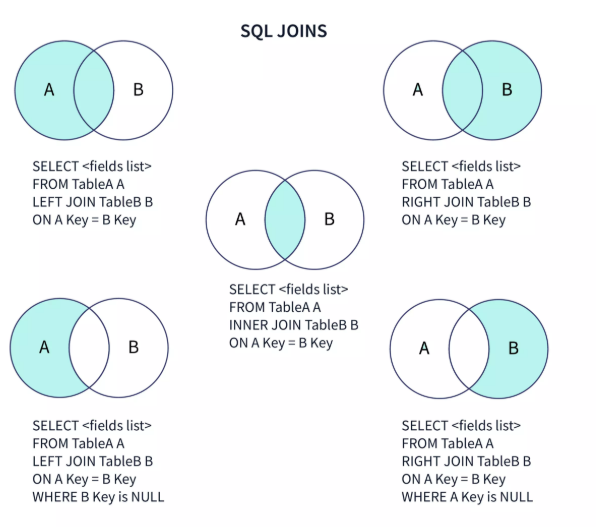

*Rys. Diagramy Venna dla LEFT/RIGHT/INNER JOIN oraz wariantów z `WHERE ... IS NULL` (scaler.com).*


In [ ]:
%%sql pg
-- invoice i invoice_line mają dokładnie jedną wspólną kolumnę: invoice_id
SELECT COUNT(*) AS wierszy
FROM   invoice NATURAL JOIN invoice_line;


In [ ]:
%%sql oracle
SELECT COUNT(*) AS wierszy
FROM   Invoice NATURAL JOIN InvoiceLine;


> **Pułapka porównawcza.** `employee NATURAL JOIN customer` zwróci **zero wierszy**, bo te tabele mają aż dziesięć wspólnych nazw kolumn (`LastName`, `FirstName`, `Address`, `City`, `State`, `Country`, `PostalCode`, `Phone`, `Fax`, `Email`) — `NATURAL JOIN` złąży po wszystkich i żadna para się nie dopasuje. `NATURAL JOIN` wydaje się bezpieczny, dopóki nie zmieni się schemat.


In [ ]:
%%sql oracle
SELECT COUNT(*) AS wierszy
FROM   Employee NATURAL JOIN Customer;


In [ ]:
%%sql mssql
-- SQL Server: NATURAL JOIN nie istnieje
SELECT COUNT(*) FROM Employee NATURAL JOIN Employee;


### Złączenie trzech i więcej tabel

Złączenia można **łączyć w łańcuch** — każdy `JOIN` dodaje następną tabelę. Pytanie: **tytuły utworów z faktury nr 1** — `invoice_line` ma tylko `track_id`, więc musimy dotrzeć do `track`:

```sql
FROM invoice i
JOIN invoice_line l ON i.invoice_id = l.invoice_id
JOIN track t        ON l.track_id = t.track_id
```

W jednym zapytaniu można mieszać `ON` i `USING` (w Oracle i PostgreSQL).


In [ ]:
%%sql pg
SELECT i.invoice_id, t.name AS utwor, l.unit_price
FROM   invoice i
JOIN   invoice_line l ON i.invoice_id = l.invoice_id
JOIN   track t        ON l.track_id = t.track_id
WHERE  i.invoice_id = 1
ORDER  BY l.invoice_line_id;


In [ ]:
%%sql mssql
SELECT i.InvoiceId, t.Name AS utwor, l.UnitPrice
FROM   Invoice i
JOIN   InvoiceLine l ON i.InvoiceId = l.InvoiceId
JOIN   Track t       ON l.TrackId = t.TrackId
WHERE  i.InvoiceId = 1
ORDER  BY l.InvoiceLineId;


In [ ]:
%%sql oracle
SELECT i.InvoiceId, t.Name AS utwor, l.UnitPrice
FROM   Invoice i
JOIN   InvoiceLine l ON i.InvoiceId = l.InvoiceId
JOIN   Track t       ON l.TrackId = t.TrackId
WHERE  i.InvoiceId = 1
ORDER  BY l.InvoiceLineId;


### Złączenia teta (θ-join) — warunek dowolny

W algebrze relacji:

```text
R1 ⋈θ R2 = σθ (R1 × R2)
```

Złączenie teta to selekcja (σ) na iloczynie kartezjańskim (×). Gdy θ to równość — mamy równozłączenie. Ale θ może być **dowolny warunek**: `<`, `>`, `BETWEEN`, `IN`, `IS NULL`, a nawet wywołanie funkcji SQL.

Przykład: **pracownicy i klienci z tego samego kraju** (nie klucz obcy! zwykłe dopasowanie atrybutu):

```sql
FROM employee e JOIN customer c ON e.country = c.country
```

Teta-złączeniem jest też porównanie dat zatrudnienia (self-join niżej).


In [ ]:
%%sql pg
SELECT e.last_name AS pracownik, e.city AS miasto_p,
       c.last_name AS klient,     c.city AS miasto_k
FROM   employee e JOIN customer c ON e.country = c.country
WHERE  e.city <> c.city
LIMIT  8;


In [ ]:
%%sql oracle
SELECT e.LastName AS pracownik, e.City AS miasto_p,
       c.LastName AS klient,    c.City AS miasto_k
FROM   Employee e JOIN Customer c ON e.Country = c.Country
WHERE  e.City <> c.City
FETCH FIRST 8 ROWS ONLY;


### Self-join — tabela złączona z samą sobą

`employee.ReportsTo → employee.EmployeeId` to klucz obcy **w tę samą tabelę**. Aby pokazać pracownika obok jego przełożonego, tabelę trzeba wystawić w `FROM` **dwa razy** pod różnymi aliasami:

```sql
FROM employee e JOIN employee m ON e.reports_to = m.employee_id
```

Fizycznie Oracle wykonuje to jako **HASH JOIN na dwóch pełnych skanach tej samej tabeli** — poniżej plan z bazy HR (ze slajdów wykładu); Chinook ma identyczny schemat zależności `manages → managed`:


In [71]:
%%sql oracle
DELETE FROM plan_table WHERE statement_id = 'test';
EXPLAIN PLAN SET STATEMENT_ID = 'test' INTO plan_table FOR SELECT * FROM employee e JOIN employee m ON e.reportsto = m.employeeid;
SELECT operation, object_name, CARDINALITY "rows", BYTES, COST, position FROM plan_table WHERE statement_id= 'test' ORDER BY id, position DESC;

6 rows affected.

operation,object_name,rows,bytes,cost,position
SELECT STATEMENT,None,7,2156,6,6
MERGE JOIN,None,7,2156,6,1
TABLE ACCESS,EMPLOYEE,8,1232,2,1
INDEX,PK_EMPLOYEE,8,None,1,1
SORT,None,7,1078,4,2
TABLE ACCESS,EMPLOYEE,7,1078,3,1


In [ ]:
%%sql oracle
SELECT e.LastName AS pracownik, e.HireDate AS prac_zatrudniony,
       m.LastName AS przelozony, m.HireDate AS przelozony_zatrudniony
FROM   Employee e JOIN Employee m ON e.ReportsTo = m.EmployeeId
ORDER  BY e.LastName;


**Pytanie teta-złączowe:** kto został zatrudniony **wcześniej** niż jego przełożony? 

Zauważ: dyrektor Adams nie występuje w wyniku — jego `ReportsTo` jest NULL i potrzebny byłby **OUTER JOIN**, żeby go pokazać.


In [44]:
%%sql pg
SELECT e.last_name AS pracownik, e.hire_date AS pracownik_zatrudniony, m.last_name AS przelozony, m.hire_date AS przelozony_zatrudniony
FROM   employee e JOIN employee m ON e.reports_to = m.employee_id
WHERE  m.hire_date > e.hire_date
ORDER  BY e.last_name;


Switching to connection 'pg'

2 rows affected.

pracownik,pracownik_zatrudniony,przelozony,przelozony_zatrudniony
Edwards,2002-05-01 00:00:00,Adams,2002-08-14 00:00:00
Peacock,2002-04-01 00:00:00,Edwards,2002-05-01 00:00:00


In [43]:
%%sql oracle
SELECT e.LastName AS pracownik, e.HireDate AS pracownik_zatrudniony, m.LastName AS przelozony, m.HireDate AS przelozony_zatrudniony
FROM   Employee e JOIN Employee m ON e.ReportsTo = m.EmployeeId
WHERE  m.HireDate > e.HireDate
ORDER  BY e.LastName;


pracownik,pracownik_zatrudniony,przelozony,przelozony_zatrudniony
Edwards,2002-05-01 00:00:00,Adams,2002-08-14 00:00:00
Peacock,2002-04-01 00:00:00,Edwards,2002-05-01 00:00:00


### Semi-join (półzłączenie) — wzorzec, nie operator

**Semi-join** to złączenie, w którym z lewej relacji bierzemy tylko te krotki, które **mają dopasowanie** w prawej — ale kolumn prawej **nie wyprowadzamy** do wyniku (i nie duplikujemy lewej strony, gdy dopasowań jest wiele).

W Oracle **nie istnieje jawna składnia** `SEMI JOIN` — to nie operator SQL, a **operacja fizyczna optymalizatora**. Semi-join realizuje się jawnie na dwa sposoby:

```sql
-- 1) EXISTS — semantyka semi-joinu, wybór lewej strony bez duplikatów
SELECT c.* FROM customer c
WHERE  EXISTS (SELECT 1 FROM invoice i WHERE i.customer_id = c.customer_id);

-- 2) JOIN + DISTINCT — to samo, ale trzeba samemu usunąć duplikaty
SELECT DISTINCT c.* FROM customer c JOIN invoice i ON c.customer_id = i.customer_id;
```

Klasyczne pytanie: **którzy klienci mają co najmniej jedną fakturę?** (59 z 59 klientów Chinook ma faktury — sprawdź oba warianty):

Uwaga: *„nie można użyć narzucającego się teta-półzłączenia, ponieważ nie jest ono w Oracle realizowane"* — semi-join z warunkami innymi niż równość (teta-półzłączenie) trzeba zawsze przepisać na `EXISTS`.


In [ ]:
%%sql pg
SELECT COUNT(*) AS klienci_z_faktura
FROM   customer c
WHERE  EXISTS (SELECT 1 FROM invoice i WHERE i.customer_id = c.customer_id);


In [ ]:
%%sql pg
SELECT COUNT(DISTINCT c.customer_id) AS klienci_z_faktura
FROM   customer c JOIN invoice i ON c.customer_id = i.customer_id;


In [ ]:
%%sql oracle
-- jawne SEMI JOIN nie istnieje: ORA-03049: SQL keyword 'SEMI' is not syntactically valid
SELECT COUNT(*) FROM Customer c SEMI JOIN Invoice i ON c.CustomerId = i.CustomerId;


### Złączenia zewnętrzne: `LEFT / RIGHT / FULL [OUTER] JOIN`

Złączenie wewnętrzne **gubi** wiersze bez dopasowania. Złączenia zewnętrzne je zachowują, uzupełniając brakującą stronę NULL-ami:

- `LEFT [OUTER] JOIN` — wszystkie wiersze lewej tabeli (+ dopasowania z prawej),
- `RIGHT [OUTER] JOIN` — wszystkie wiersze prawej tabeli,
- `FULL [OUTER] JOIN` — wszystkie wiersze obu tabel.

Słowo `OUTER` jest opcjonalne. Diagramy Venna obu wariantów (scaler.com):

1. `FULL OUTER JOIN` — cała suma zbiorów,
2. `FULL OUTER JOIN ... WHERE klucz IS NULL` — symetryczna różnica (wiersze bez dopasowania z obu stron).


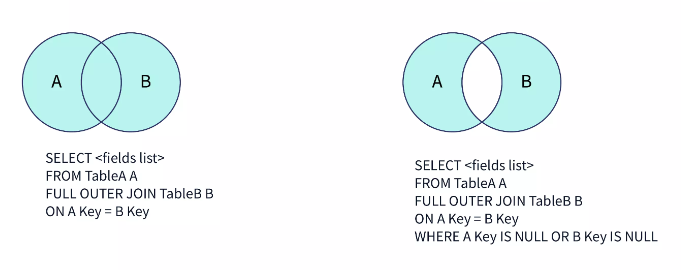

*Rys. FULL OUTER JOIN (lewa) i anty-złączenie pełne przez WHERE ... IS NULL (prawa).*


In [ ]:
%%sql pg
-- LEFT JOIN + IS NULL = klienci bez faktur (anti-join)
-- wynik pusty: w Chinook każdy klient ma fakturę — celowo pokazujemy anti-join, który nic nie zwraca
SELECT c.customer_id, c.last_name
FROM   customer c
LEFT   JOIN invoice i ON c.customer_id = i.customer_id
WHERE  i.invoice_id IS NULL;


customer_id,last_name


In [ ]:
%%sql oracle
-- anti-join w starej składni Oracle: pracownicy bez klientów (5 osób); (+) po stronie "słabszej" tabeli
SELECT e.EmployeeId, e.LastName
FROM   Employee e, Customer c
WHERE  e.EmployeeId = c.SupportRepId(+)
AND    c.CustomerId IS NULL;


Switching to connection 'oracle'

employeeid,lastname
1,Adams
2,Edwards
6,Mitchell
7,King
8,Callahan


**Stara składnia Oracle `(+)`:** operator `(+)` przy kolumnie tabeli prawej oznacza lewostronne złączenie zewnętrzne (`LEFT JOIN`) — przykład powyżej: pracownicy bez klientów. To składnia sprzed SQL:1992 — **od Oracle 9i zalecana jest składnia ANSI**; `(+)` zostaje w kodzie legacy. Dwie rzeczy warte uwagi:
- `(+)` w warunku nie wyrazi `FULL OUTER JOIN` — w starej składni wymaga to `UNION` dwóch złączeń zewnętrznych,
- SQL Server i PostgreSQL nie rozpoznają `(+)`.


**Anti-join** — obraz lustrzany semi-joinu: wiersze **bez** dopasowania. Pracownicy, którzy nie obsługują żadnego klienta (5 osób w Chinook):

```sql
WHERE NOT EXISTS (SELECT 1 FROM customer c WHERE c.support_rep_id = e.employee_id)
-- równoważnie:
LEFT JOIN customer c ON ... WHERE c.customer_id IS NULL
```

Zgodnie z notatkami z wykładu: **NULL-e nie dopasowują się w złączeniach wewnętrznych** — dokładnie dlatego `LEFT JOIN ... WHERE klucz_drugiej IS NULL` jest niezawodnym anti-joinem: NULL w prawej tabeli oznacza „brak dopasowania", nigdy „dopasowanie do NULL-a".


In [ ]:
%%sql pg
SELECT e.last_name
FROM   employee e
WHERE  NOT EXISTS (SELECT 1 FROM customer c WHERE c.support_rep_id = e.employee_id);


In [ ]:
%%sql oracle
SELECT e.LastName
FROM   Employee e
WHERE  NOT EXISTS (SELECT 1 FROM Customer c WHERE c.SupportRepId = e.EmployeeId);


### `FULL OUTER JOIN` na żywo

Pytanie zaliczeniowe z wykładu: **pracownicy i ich klienci — pokaż obustronne braki dopasowania** (`NVL`/`COALESCE` z §12 zamienia NULL w zrozumiały tekst):

```sql
SELECT NVL(e.last_name,'—') AS pracownik, NVL(c.last_name,'brak klienta') AS klient
FROM   employee e FULL OUTER JOIN customer c ON e.employee_id = c.support_rep_id
```

W Chinook: 64 wiersze, 5 pracowników bez klientów, **0 klientów bez pracownika**. Screen z HR poniżej pokazuje oba typy braków: pracownicy bez działu (NULL z prawej) i działy bez pracowników (NULL z lewej).


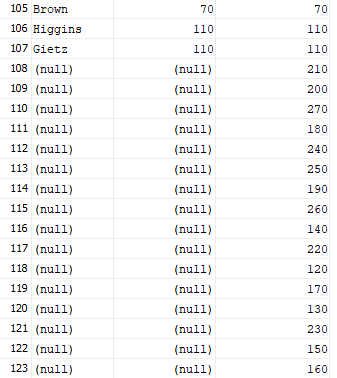

In [ ]:
%%sql oracle
SELECT NVL(e.LastName, '— (klient bez opiekuna)') AS pracownik,
       NVL(c.LastName, 'brak klienta')           AS klient
FROM   Employee e FULL OUTER JOIN Customer c ON e.EmployeeId = c.SupportRepId
ORDER  BY 1
FETCH FIRST 6 ROWS ONLY;


In [ ]:
%%sql pg
SELECT COUNT(*)                                   AS wiersze,
       COUNT(*) FILTER (WHERE c.customer_id IS NULL) AS pracownikow_bez_klientow,
       COUNT(*) FILTER (WHERE e.employee_id IS NULL) AS klientow_bez_pracownika
FROM   employee e FULL OUTER JOIN customer c ON e.employee_id = c.support_rep_id;


In [ ]:
%%sql mssql
SELECT COUNT(*) AS wiersze,
       SUM(CASE WHEN c.CustomerId IS NULL THEN 1 ELSE 0 END) AS PracownikowBezKlientow,
       SUM(CASE WHEN e.EmployeeId IS NULL THEN 1 ELSE 0 END) AS KlientowBezPracownika
FROM   Employee e FULL OUTER JOIN Customer c ON e.EmployeeId = c.SupportRepId;


### T-SQL: co SQL Server *nie* ma (i co ma własne)

| Cecha | Oracle | PostgreSQL | SQL Server (T-SQL) |
|---|---|---|---|
| `JOIN ... ON` | ✔ | ✔ | ✔ (`INNER JOIN` tylko w `FROM`) |
| `USING` | ✔ | ✔ | **brak** — zawsze `ON` |
| `NATURAL JOIN` | ✔ (pułapka!) | ✔ (pułapka!) | **brak** |
| stara składnia przecinkowa (`FROM a, b WHERE ...`) | ✔ | ✔ | ✔ (tylko wewnętrzne) |
| `(+)` | ✔ legacy | brak | brak |
| `LEFT/RIGHT/FULL [OUTER] JOIN` | ✔ | ✔ | ✔ (`OUTER` opcjonalne) |
| `CROSS JOIN` | ✔ | ✔ | ✔ (`CROSS APPLY` dla wyrażeń tabelarycznych) |

Reguła T-SQL: **`INNER JOIN` da się zapisać warunkiem w `WHERE` (stara składnia przecinkowa), ale `LEFT/RIGHT/FULL OUTER` i `CROSS JOIN` muszą być jawnie w `FROM`** — w T-SQL nie ma operatora analogue do `(+)`, złączenia zewnętrzne zapisuje się tylko składnią ANSI.


In [ ]:
%%sql mssql
-- T-SQL: wewnętrzne złączenie dowolną z metod, zewnętrzne tylko przez FROM
SELECT e.LastName AS pracownik, c.LastName AS klient
FROM   Employee e LEFT OUTER JOIN Customer c ON e.EmployeeId = c.SupportRepId
WHERE  c.CustomerId IS NULL;


## 20. Operatory zbiorowe

Wynik `SELECT`-a jest relacją, więc dwa wyniki można traktować jak zbiory i łączyć:

| Operator | Działanie | Uwagi |
|---|---|---|
| `UNION` | suma zbiorów | **usuwa duplikaty** (niejawne DISTINCT) |
| `UNION ALL` | suma wielozbiorów | zachowuje duplikaty — szybszy |
| `INTERSECT` | część wspólna | Oracle/pg/mssql — standard; duplikaty usuwane |
| `MINUS` / `EXCEPT` | różnica zbiorów | Oracle: `MINUS` (od 21c także `EXCEPT`); SQL Server i PostgreSQL: `EXCEPT` |

> Oba argumenty muszą mieć **zgodną liczbę kolumn** i typy porównywalne. Nazwy kolumn wyniku pochodzą z pierwszego zapytania.

Miasta klientów, w których nie mieszkają pracownicy (przykład różnic dialektów):

In [ ]:
%%sql pg
-- miasta klientów, w których nie ma pracownika
SELECT city FROM customer
EXCEPT
SELECT city FROM employee;

52 rows affected.

city
Budapest
Porto
Reno
London
Paris
New York
Salt Lake City
Prague
Dijon
Rome


In [ ]:
%%sql oracle
SELECT City FROM Customer
MINUS
SELECT City FROM Employee;

Switching to connection 'oracle'

city
São José dos Campos
Stuttgart
Montréal
Oslo
Prague
Vienne
Brussels
Copenhagen
São Paulo
Rio de Janeiro


In [ ]:
%%sql mssql
SELECT City FROM Customer
EXCEPT
SELECT City FROM Employee;

Switching to connection 'mssql'

City
Amsterdam
Bangalore
Berlin
Bordeaux
Boston
Brasília
Brussels
Budapest
Buenos Aires
Chicago


Kraje, w których mieszkają i klienci, i pracownicy:

In [ ]:
%%sql pg
SELECT country FROM customer
INTERSECT
SELECT country FROM employee;

Switching to connection 'pg'

1 rows affected.

country
Canada


`UNION` vs `UNION ALL` — policzmy wiersze wyniku na tych samych danych. `UNION` usunął duplikaty (67 wierszy wejściowych → 24 kraje), `UNION ALL` zachował wszystkie:

In [ ]:
%%sql pg
SELECT COUNT(*) AS po_union      -- 24
FROM   (SELECT country FROM customer
        UNION
        SELECT country FROM employee) u;

SELECT COUNT(*) AS po_union_all  -- 67
FROM   (SELECT country FROM customer
        UNION ALL
        SELECT country FROM employee) u;

1 rows affected.

1 rows affected.

po_union_all
67


**Zasady składania operatorów zbiorowych:**

1. nazwy kolumn wyniku pochodzą z **pierwszego** zapytania,
2. `ORDER BY` występuje **raz, na końcu całości** — i odnosi się do wyniku złożonego,
3. w `ORDER BY` można używać **tylko pozycji** (albo nazw kolumn pierwszego zapytania) — wyrażenia z drugiego zapytania są niedostępne,
4. Operatory można zagnieżdżać — kolejność:  `INTERSECT`/`EXCEPT` > `UNION ALL` > `UNION` (left-associative); gdy potrzebna inna, **nawiasuj podzapytania**. **`INTERSECT` (Oracle: też `MINUS`) wiąże mocniej niż `UNION [ALL]`**, a operatory o tej samej sile wiązania są ewaluowane od lewej.

## 21. Hierarchie w danych — CONNECT BY i CTE

### Związek definiujący hierarchię

**Zwiazek definiujący hierarchię to klucz obcy powiązany z kluczem głównym tej samej relacji.** W Chinook: `Employee.ReportsTo → Employee.EmployeeId` — każdy pracownik ma przełożonego, którym też jest pracownik. Prezes (`Adams`) ma `ReportsTo = NULL`.

```mermaid
flowchart TD
    A["Adams (1)<br/>General Manager"] --> E["Edwards (2)<br/>Sales Manager"]
    A --> M["Mitchell (6)<br/>IT Manager"]
    E --> P["Peacock (3)"]
    E --> Pa["Park (4)"]
    E --> J["Johnson (5)"]
    M --> K["King (7)"]
    M --> C["Callahan (8)"]
```

### Oracle: CONNECT BY i START WITH

Oracle rozszerza `SELECT` o klauzule przetwarzania hierarchii:

- `START WITH warunek` — wybiera korzeń (wiersze spełniające warunek; jeśli n wierszy spełnia — powstaje n drzew),
- `CONNECT BY warunek` — definiuje, która krotka ma być dołączona jako liść do aktualnego węzła; słowo **`PRIOR`** wskazuje atrybut nadrzędny (z aktualnej krotki nadrzędnej pobierana jest wartość do porównania z atrybutem podrzędnym):

```sql
CONNECT BY PRIOR employee_id = reports_to
-- "rodzic ma employee_id rowne reports_to dziecka"
```

Oracle przetwarza zapytanie hierarchiczne tak: najpierw złączenie (jeśli jest), potem warunek `CONNECT BY`, potem pozostałe predykaty `WHERE` (indywidualnie, wiersz po wierszu — **WHERE nie przycina gałęzi, tylko liście**).

Podstawowe zapytanie hierarchiczne:

In [ ]:
%%sql oracle
SELECT EmployeeId,
       LastName,
       ReportsTo,
       LEVEL AS poziom
FROM   Employee
START WITH ReportsTo IS NULL
CONNECT BY PRIOR EmployeeId = ReportsTo;

Switching to connection 'oracle'

employeeid,lastname,reportsto,poziom
1,Adams,None,1
2,Edwards,1,2
3,Peacock,2,3
4,Park,2,3
5,Johnson,2,3
6,Mitchell,1,2
7,King,6,3
8,Callahan,6,3


Pseudokolumna **`LEVEL`** określa głębokość krotki w drzewie (korzeń = 1). Sekcja harmonizuje porządek w obrębie gałęzi przez **`ORDER SIBLINGS BY`** — zwykłe `ORDER BY` zniszczyłoby strukturę drzewa:

In [ ]:
%%sql oracle
SELECT LEVEL AS poziom,
       LPAD(' ', 2*(LEVEL-1)) || LastName AS drzewo,
       EmployeeId
FROM   Employee
START WITH ReportsTo IS NULL
CONNECT BY PRIOR EmployeeId = ReportsTo
ORDER  SIBLINGS BY LastName;

poziom,drzewo,employeeid
1,Adams,1
2,Edwards,2
3,Johnson,5
3,Park,4
3,Peacock,3
2,Mitchell,6
3,Callahan,8
3,King,7


Wynik czytamy od góry — z wcięciami zbudowanymi `LPAD`-em:

```text
Adams
  Edwards
    Johnson
    Park
    Peacock
  Mitchell
    Callahan
    King
```

Dodatkowe narzędzia hierarchiczne Oracle:

- **`CONNECT_BY_ROOT` atrybut** — wartość atrybutu w korzeniu bieżącego drzewa,
- **`CONNECT_BY_ISLEAF`** — 1, gdy bieżąca krotka jest liściem,
- **`SYS_CONNECT_BY_PATH(atrybut, separator)`** — ścieżka od korzenia do bieżącej krotki zbudowana z wartości atrybutu,
- **`NOCYCLE` + `CONNECT_BY_ISCYCLE`** — gdy dane zawierają pętlę (wiersz jest swoim własnym przodkiem), zwykły `CONNECT BY` zwraca błąd `ORA-01436`; `NOCYCLE` pozwala zwrócić wiersze mimo pętli, a `CONNECT_BY_ISCYCLE` wskazuje, gdzie pętla powstaje.

In [ ]:
%%sql oracle
SELECT LPAD(' ', 2*(LEVEL-1)) || LastName           AS drzewo,
       SYS_CONNECT_BY_PATH(LastName, '/')           AS sciezka,
       CONNECT_BY_ISLEAF                            AS lisc,
       CONNECT_BY_ROOT LastName                     AS korzen
FROM   Employee
WHERE  LEVEL <= 3
START  WITH LastName = 'Edwards'
CONNECT BY NOCYCLE PRIOR EmployeeId = ReportsTo;

drzewo,sciezka,lisc,korzen
Edwards,/Edwards,0,Edwards
Peacock,/Edwards/Peacock,1,Edwards
Park,/Edwards/Park,1,Edwards
Johnson,/Edwards/Johnson,1,Edwards


### PostgreSQL i SQL Server: rekurencyjne CTE

SQL Server **nie ma** `CONNECT BY`. Stosuje **CTE** (*Common Table Expressions*) z rekurencją: `WITH ... AS (...)` ze słowem kluczowym `RECURSIVE` (PostgreSQL) lub bez niego (SQL Server — rekurencja jest zawsze dozwolona w CTE). Większość dialektów używa deklaracji z `WITH RECURSIVE` (PostgreSQL) lub po prostu `WITH` z rekurencją (Oracle od 11gR2, SQL Server).

Ten sam spis pracowników co zapytanie CONNECT BY powyżej:

In [ ]:
%%sql pg
WITH RECURSIVE hierarchia(id, nazwisko, poziom) AS (
    -- czlon (kotwica): korzen hierarchii
    SELECT employee_id, last_name, 1
    FROM   employee
    WHERE  reports_to IS NULL
    UNION ALL
    -- czlon rekurencyjny: podwladni poprzedniego poziomu
    SELECT e.employee_id, e.last_name, h.poziom + 1
    FROM   employee e
    JOIN   hierarchia h ON e.reports_to = h.id
)
SELECT poziom, nazwisko, id
FROM   hierarchia
ORDER  BY poziom, nazwisko;

Switching to connection 'pg'

8 rows affected.

poziom,nazwisko,id
1,Adams,1
2,Edwards,2
2,Mitchell,6
3,Callahan,8
3,Johnson,5
3,King,7
3,Park,4
3,Peacock,3


In [ ]:
%%sql mssql
WITH hierarchia(id, nazwisko, poziom) AS (
    SELECT EmployeeId, LastName, 1
    FROM   Employee
    WHERE  ReportsTo IS NULL
    UNION ALL
    SELECT e.EmployeeId, e.LastName, h.poziom + 1
    FROM   Employee e
    JOIN   hierarchia h ON e.ReportsTo = h.id
)
SELECT poziom, nazwisko, id
FROM   hierarchia
ORDER  BY poziom, nazwisko;

Switching to connection 'mssql'

poziom,nazwisko,id
1,Adams,1
2,Edwards,2
2,Mitchell,6
3,Callahan,8
3,Johnson,5
3,King,7
3,Park,4
3,Peacock,3


| | Oracle | PostgreSQL | SQL Server |
|---|---|---|---|
| zapytania hierarchiczne | `CONNECT BY` + `START WITH` | CTE z `WITH RECURSIVE` | CTE z `WITH` (bez RECURSIVE) |
| głębokość węzła | pseudokolumna `LEVEL` | kolumna licznika w CTE | kolumna licznika w CTE |
| porządek w gałęzi | `ORDER SIBLINGS BY` |dowolny — trzeba budować ścieżkę | dowolny — trzeba budować ścieżkę |

> **Zapamiętaj:** CTE z rekurencją to standard SQL:1999 — jest dostępne we wszystkich trzech DBMS-ach, więc w kodzie przenośnym wybieramy CTE. `CONNECT BY` bywa zwięźlejsze dla prostych hierarchii i ma unikalne dodatki (`SYS_CONNECT_BY_PATH`, `CONNECT_BY_ROOT`).

## 22. Podsumowanie wykładu

### Najważniejsze pojęcia

- `SELECT` jest jedynym poleceniem DQL; jego wynik jest relacją (domknięcie) — stąd podzapytania,
- kolejność zapisu ≠ kolejność wykonania: `FROM` → `WHERE` → `GROUP BY` → `HAVING` → `SELECT` → `DISTINCT` → `ORDER BY` → `FETCH/LIMIT/TOP`,
- `DISTINCT` usuwa duplikaty; aliasy i literały wzbogacją listę `SELECT`,
- `NULL` to brak wartości: porównanie z NULL daje UNKNOWN, arytmetyka z NULL daje NULL, znacznik `IS [NOT] NULL` jest jedynym bezpiecznym testem,
- 3VL: `FALSE AND NULL = FALSE`, `TRUE OR NULL = TRUE`,
- `WHERE` filtruje wiersze, `HAVING` filtruje grupy, agregaty liczą po NULL-ach (poza `COUNT(*)`), pusty zbiór → `SUM`/`AVG`/`MIN`/`MAX` = NULL, ale `COUNT` = 0,
- funkcje wbudowane: znakowe (`LENGTH`, `SUBSTR`/`LEFT`/`RIGHT`, `INSTR`/`CHARINDEX`, `TRIM`, `INITCAP`), matematyczne (`ROUND`, `TRUNC`, `MOD`/`%`, `CEIL`, `FLOOR`) i dat (`TO_CHAR`/`FORMAT`, `EXTRACT`, `ADD_MONTHS`/`DATEADD`/`interval`, `DATEDIFF`) — nazwy się różnią, semantyka podobna,
- `NVL`/`ISNULL`/`COALESCE` podmieniają NULL; `DECODE` (Oracle) i `CASE` (standard) wnoszą logikę warunkową,
- podzapytania: nieskorelowane wykonują się raz, skorelowane — dla każdego wiersza; w `SELECT` tylko skalarne; w `FROM` to inline view,
- `IN`, `ANY`, `ALL`, `EXISTS`/`NOT EXISTS` spinają zapytanie z podzapytaniem — `NOT IN` jest niebezpieczny przy NULL-ach w podzapytaniu,
- złączenia poziome: `JOIN ... ON` (ANSI), `USING` (Oracle/PG — nie T-SQL), `NATURAL JOIN` (pułapka wspólnych nazw), `LEFT/RIGHT/FULL [OUTER] JOIN`, self-join przez aliasy, semi-join = `EXISTS`, anti-join = `LEFT JOIN ... IS NULL`; w Oracle `(+)` to legacy `LEFT JOIN`,
- operatory zbiorowe: `UNION [ALL]`, `INTERSECT`, `MINUS`/`EXCEPT` — składają dwa wyniki w jeden (`ORDER BY` tylko raz, na końcu),
- hierarchie: Oracle `CONNECT BY`/`START WITH` (+`LEVEL`, `SYS_CONNECT_BY_PATH`, `NOCYCLE`), PostgreSQL/SQL Server — rekurencyjne CTE (standard).

### Checklista umiejętności

Potrafisz już: ograniczyć wynik w trzech dialektach, złączyć dwie i więcej tabel (`ON`/`USING`/`NATURAL`, wewnętrznie i zewnętrznie), bezpiecznie porównać NULL, użyć funkcji znakowych, matematycznych i daty w trzech dialektach, zbudować raport z `GROUP BY` + `HAVING`, rozbić pytanie na zapytanie + podzapytania, połączyć wyniki operatormi zbiorowymi, przejść hierarchię w głąb w Oracle i w CTE.